In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

conn = sqlite3.connect("agriculture.db")

print("Connected to SQLite successfully!")

Connected to SQLite successfully!


In [2]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    conn
)

display(tables)

,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean


In [3]:
crop_clean = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_clean;",
    conn
)

train_clean = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_clean;",
    conn
)

test_clean = pd.read_sql_query(
    "SELECT * FROM agri_yield_test_clean;",
    conn
)

In [4]:
print("Crop Recommendation:", crop_clean.shape)
print("Yield Train:", train_clean.shape)
print("Yield Test:", test_clean.shape)

Crop Recommendation: (2200, 23)
Yield Train: (10000, 9)
Yield Test: (2000, 8)


In [5]:
crop_numeric = crop_clean.select_dtypes(
    include=np.number
).columns.tolist()

crop_categorical = crop_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:")
print(crop_numeric)

print("\nCategorical Columns:")
print(crop_categorical)

Numerical Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

Categorical Columns:
['label']


In [6]:
crop_numeric = crop_clean.select_dtypes(
    include=np.number
).columns.tolist()

crop_categorical = crop_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:")
print(crop_numeric)

print("\nCategorical Columns:")
print(crop_categorical)

Numerical Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

Categorical Columns:
['label']


In [7]:
crop_clean.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,2200.0,NaN,NaN,NaN,50.551818,36.917334,0.0,21.0,37.0,84.25,140.0
P,2200.0,NaN,NaN,NaN,53.362727,32.985883,5.0,28.0,51.0,68.0,145.0
K,2200.0,NaN,NaN,NaN,48.149091,50.647931,5.0,20.0,32.0,49.0,205.0
temperature,2200.0,NaN,NaN,NaN,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,NaN,NaN,NaN,71.481779,22.263812,14.25804,60.261953,80.473146,89.948771,99.981876
ph,2200.0,NaN,NaN,NaN,6.46948,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,NaN,NaN,NaN,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117
label,2200,22,rice,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_moisture,2200.0,NaN,NaN,NaN,20.151388,5.79372,10.02426,15.179949,20.088481,25.255146,29.99786
soil_type,2200.0,NaN,NaN,NaN,1.991364,0.812263,1.0,1.0,2.0,3.0,3.0


In [8]:
train_clean.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
field_id,10000,10000,F00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_ph,10000.0,NaN,NaN,NaN,6.508556,0.579959,5.5,6.0,6.51,7.01,7.5
organic_matter,10000.0,NaN,NaN,NaN,2.748447,0.717645,1.5,2.13,2.75,3.36,4.0
sand_pct,10000.0,NaN,NaN,NaN,44.95785,8.65291,30.0,37.5,45.0,52.4,60.0
temperature,10000.0,NaN,NaN,NaN,26.99392,1.736847,24.0,25.5,27.0,28.5,30.0
humidity,10000.0,NaN,NaN,NaN,74.5234,5.775101,65.0,70.0,75.0,80.0,84.0
rainfall,10000.0,NaN,NaN,NaN,140.03385,23.026794,100.0,120.2,140.1,160.2,180.0
ndvi,10000.0,NaN,NaN,NaN,0.574883,0.100168,0.4,0.49,0.57,0.66,0.75
yield,10000.0,NaN,NaN,NaN,4251.9764,436.533109,3500.2,3868.05,4257.15,4638.325,5000.0


In [9]:
print("Crop Dataset Missing Values")
print(crop_clean.isnull().sum())

print("\nYield Train Missing Values")
print(train_clean.isnull().sum())

print("\nYield Test Missing Values")
print(test_clean.isnull().sum())

Crop Dataset Missing Values
N                         0
P                         0
K                         0
temperature               0
humidity                  0
ph                        0
rainfall                  0
label                     0
soil_moisture             0
soil_type                 0
sunlight_exposure         0
wind_speed                0
co2_concentration         0
organic_matter            0
irrigation_frequency      0
crop_density              0
pest_pressure             0
fertilizer_usage          0
growth_stage              0
urban_area_proximity      0
water_source_type         0
frost_risk                0
water_usage_efficiency    0
dtype: int64

Yield Train Missing Values
field_id          0
soil_ph           0
organic_matter    0
sand_pct          0
temperature       0
humidity          0
rainfall          0
ndvi              0
yield             0
dtype: int64

Yield Test Missing Values
field_id          0
soil_ph           0
organic_matter    0
sand_pc

In [10]:
crop_missing_pct = (
    crop_clean.isnull().sum()
    / len(crop_clean)
) * 100

yield_missing_pct = (
    train_clean.isnull().sum()
    / len(train_clean)
) * 100

print("Crop Missing Percentage:")
print(crop_missing_pct)

print("\nYield Missing Percentage:")
print(yield_missing_pct)

Crop Missing Percentage:
N                         0.0
P                         0.0
K                         0.0
temperature               0.0
humidity                  0.0
ph                        0.0
rainfall                  0.0
label                     0.0
soil_moisture             0.0
soil_type                 0.0
sunlight_exposure         0.0
wind_speed                0.0
co2_concentration         0.0
organic_matter            0.0
irrigation_frequency      0.0
crop_density              0.0
pest_pressure             0.0
fertilizer_usage          0.0
growth_stage              0.0
urban_area_proximity      0.0
water_source_type         0.0
frost_risk                0.0
water_usage_efficiency    0.0
dtype: float64

Yield Missing Percentage:
field_id          0.0
soil_ph           0.0
organic_matter    0.0
sand_pct          0.0
temperature       0.0
humidity          0.0
rainfall          0.0
ndvi              0.0
yield             0.0
dtype: float64


In [11]:
print(crop_clean.columns.tolist())

['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']


In [12]:
crop_target = "label"

In [13]:
print("Target:", crop_target)

print("\nTarget Data Type:")
print(crop_clean[crop_target].dtype)

print("\nNumber of Classes:")
print(crop_clean[crop_target].nunique())

print("\nClasses:")
print(crop_clean[crop_target].unique())

Target: label

Target Data Type:
object

Number of Classes:
22

Classes:
['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [14]:
print("Target:", crop_target)

print("\nTarget Data Type:")
print(crop_clean[crop_target].dtype)

print("\nNumber of Classes:")
print(crop_clean[crop_target].nunique())

print("\nClasses:")
print(crop_clean[crop_target].unique())

Target: label

Target Data Type:
object

Number of Classes:
22

Classes:
['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [15]:
crop_class_counts = crop_clean[crop_target].value_counts()

print(crop_class_counts)

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


In [16]:
crop_class_percentage = (
    crop_clean[crop_target]
    .value_counts(normalize=True)
    * 100
)

print(crop_class_percentage.round(2))

label
rice           4.55
maize          4.55
jute           4.55
cotton         4.55
coconut        4.55
papaya         4.55
orange         4.55
apple          4.55
muskmelon      4.55
watermelon     4.55
grapes         4.55
mango          4.55
banana         4.55
pomegranate    4.55
lentil         4.55
blackgram      4.55
mungbean       4.55
mothbeans      4.55
pigeonpeas     4.55
kidneybeans    4.55
chickpea       4.55
coffee         4.55
Name: proportion, dtype: float64


In [17]:
crop_target_summary = pd.DataFrame({
    "Count": crop_class_counts,
    "Percentage": crop_class_percentage.round(2)
})

display(crop_target_summary)

,Count,Percentage
label,,
rice,100,4.55
maize,100,4.55
jute,100,4.55
cotton,100,4.55
coconut,100,4.55
papaya,100,4.55
orange,100,4.55
apple,100,4.55
muskmelon,100,4.55


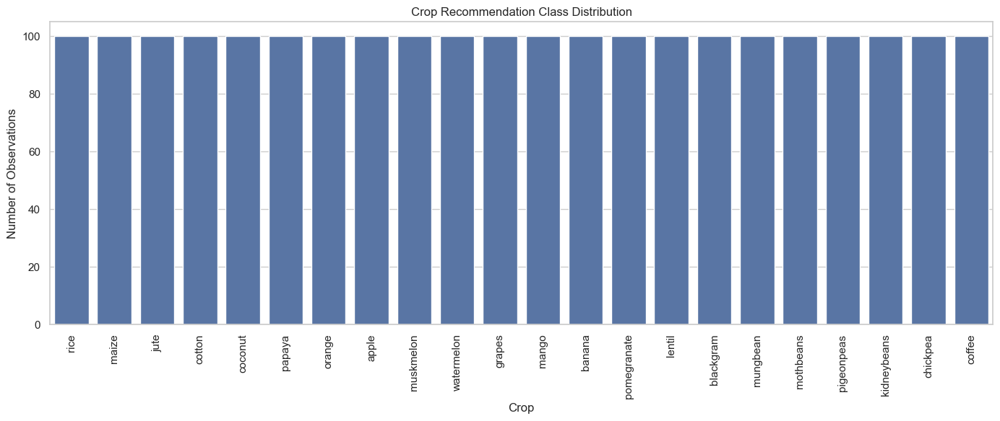

In [18]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=crop_clean,
    x=crop_target,
    order=crop_clean[crop_target].value_counts().index
)

plt.title("Crop Recommendation Class Distribution")
plt.xlabel("Crop")
plt.ylabel("Number of Observations")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

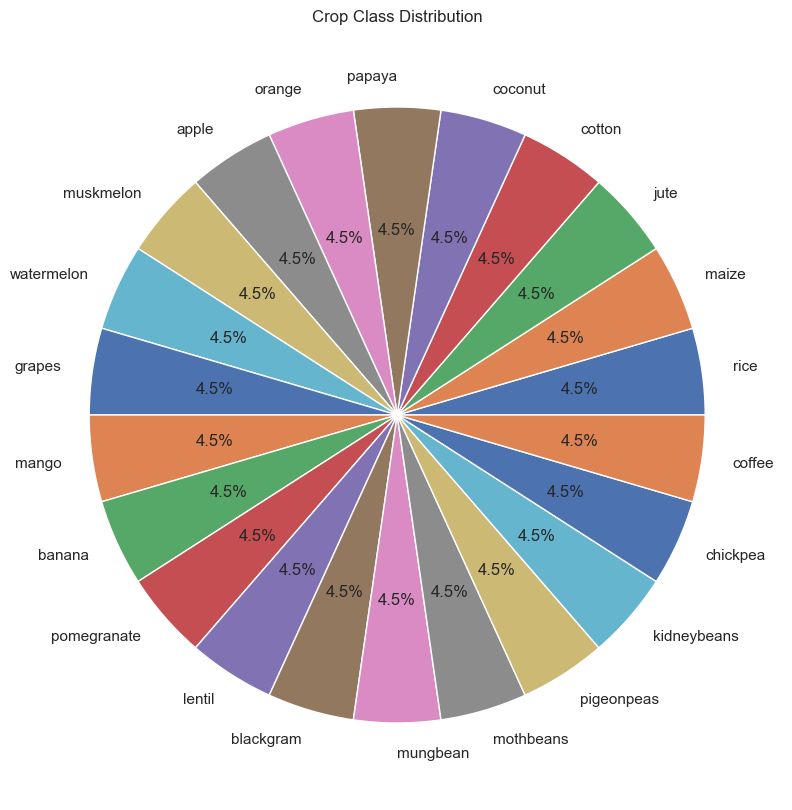

In [19]:
plt.figure(figsize=(10, 10))

crop_clean[crop_target].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Crop Class Distribution")
plt.ylabel("")

plt.show()

In [20]:
class_counts = crop_clean[crop_target].value_counts()

max_class = class_counts.max()
min_class = class_counts.min()

imbalance_ratio = max_class / min_class

print("Largest class:", max_class)
print("Smallest class:", min_class)
print("Max/Min Ratio:", round(imbalance_ratio, 2))

Largest class: 100
Smallest class: 100
Max/Min Ratio: 1.0


In [21]:
print(train_clean.columns.tolist())

['field_id', 'soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']


In [22]:
yield_target = "yield"

In [23]:
print("Target:", yield_target)

print("\nData Type:")
print(train_clean[yield_target].dtype)

print("\nNumber of Unique Values:")
print(train_clean[yield_target].nunique())

Target: yield

Data Type:
float64

Number of Unique Values:
7276


In [24]:
yield_stats = train_clean[yield_target].describe()

display(yield_stats)

count    10000.000000
mean      4251.976400
std        436.533109
min       3500.200000
25%       3868.050000
50%       4257.150000
75%       4638.325000
max       5000.000000
Name: yield, dtype: float64

In [25]:
print("Mean:", train_clean[yield_target].mean())
print("Median:", train_clean[yield_target].median())
print("Standard Deviation:", train_clean[yield_target].std())
print("Minimum:", train_clean[yield_target].min())
print("Maximum:", train_clean[yield_target].max())

Mean: 4251.9764
Median: 4257.15
Standard Deviation: 436.5331090909051
Minimum: 3500.2
Maximum: 5000.0


In [26]:
yield_skewness = train_clean[yield_target].skew()

print("Yield Skewness:", yield_skewness)

Yield Skewness: -0.010735120947819605


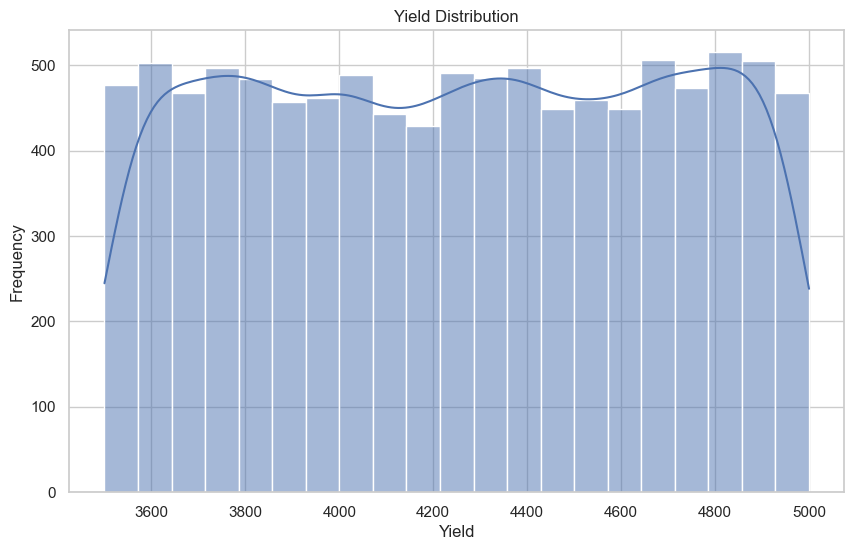

In [27]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=train_clean,
    x=yield_target,
    kde=True
)

plt.title("Yield Distribution")
plt.xlabel("Yield")
plt.ylabel("Frequency")

plt.show()

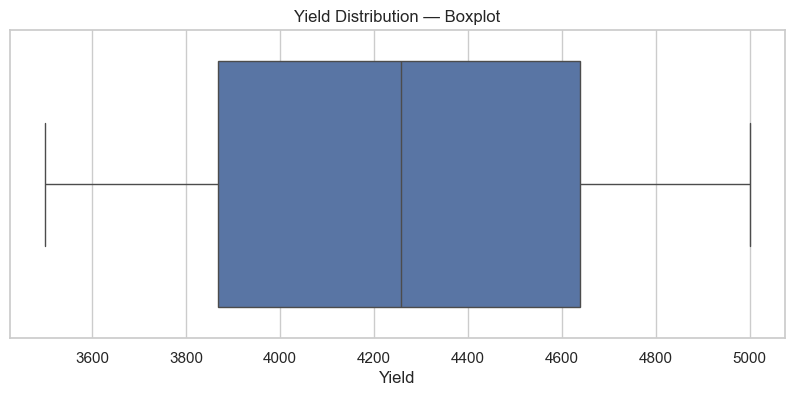

In [28]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=train_clean[yield_target]
)

plt.title("Yield Distribution — Boxplot")
plt.xlabel("Yield")

plt.show()

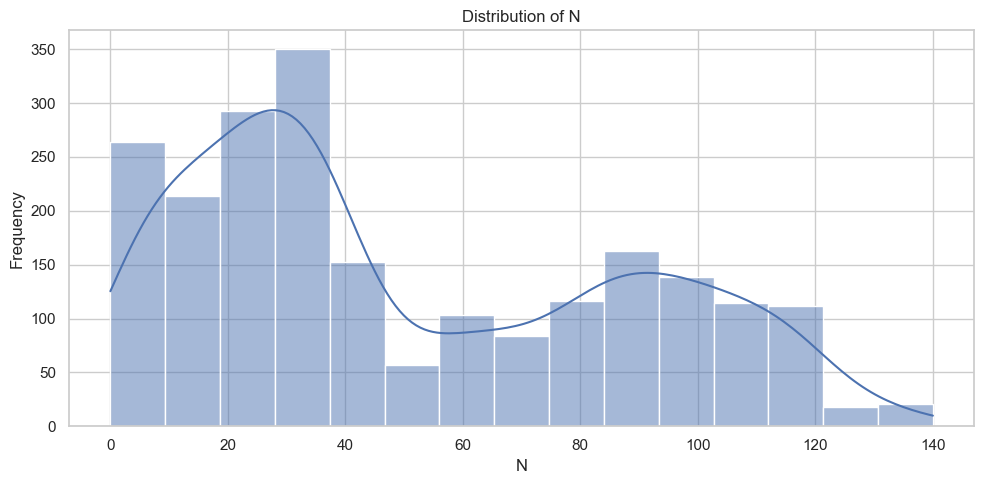

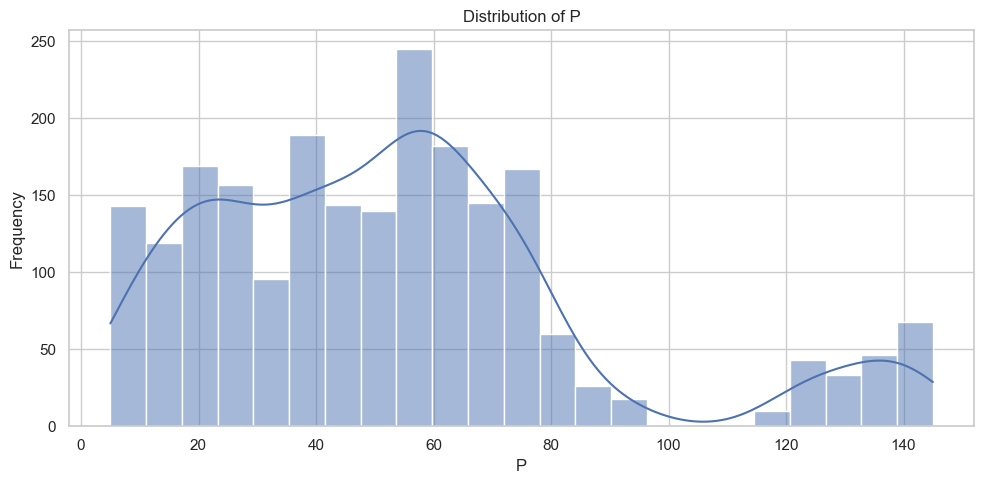

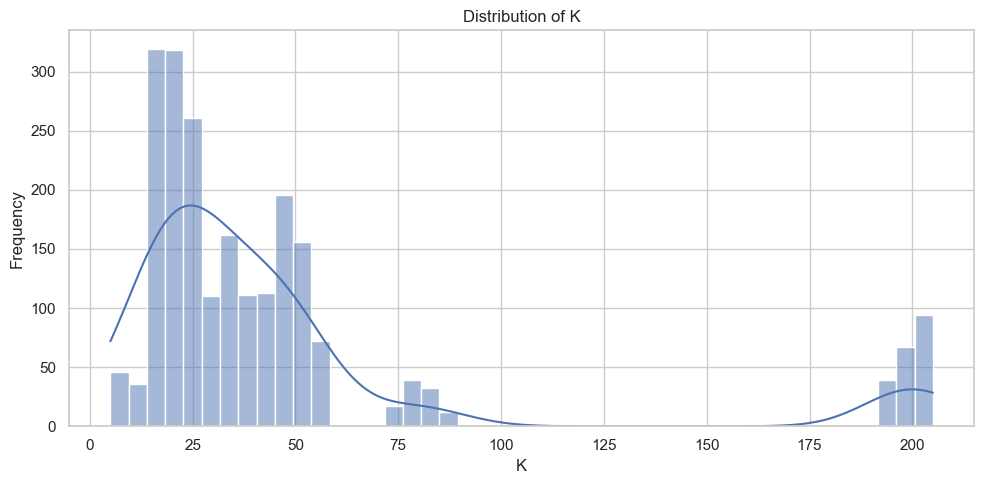

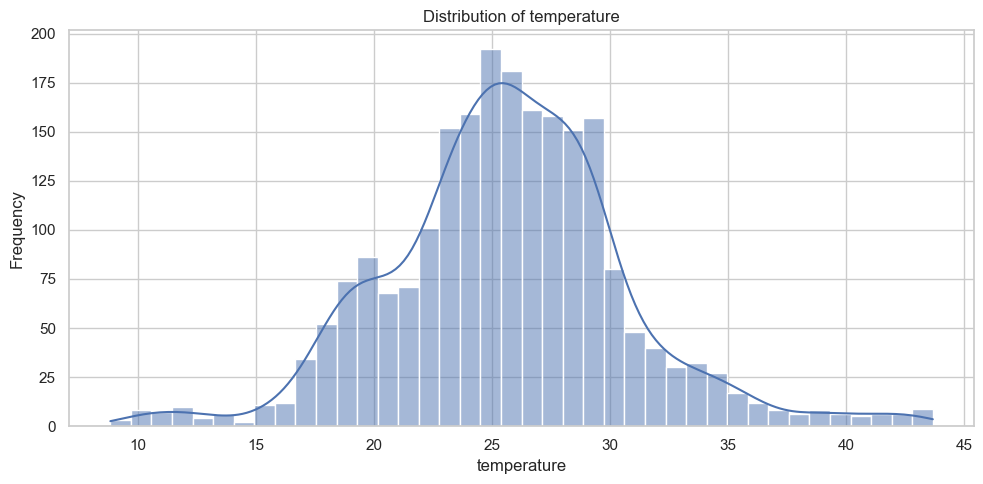

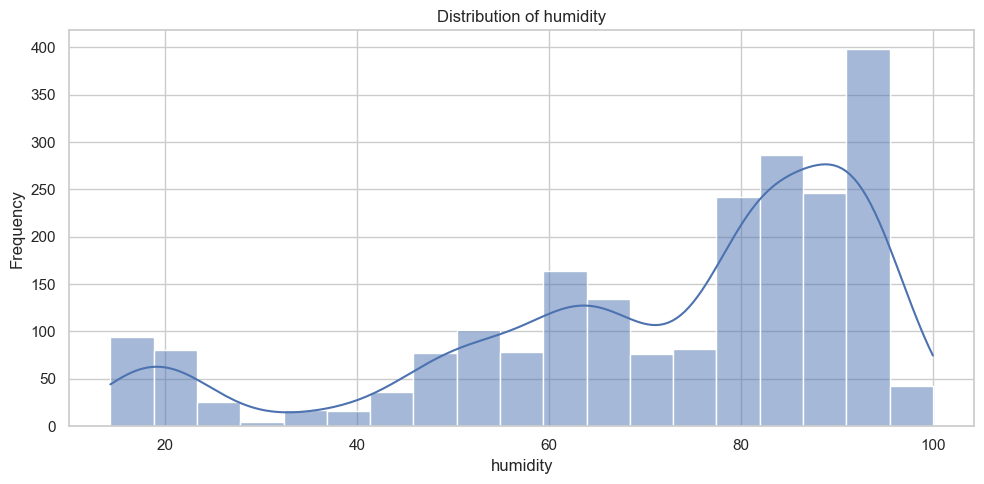

...

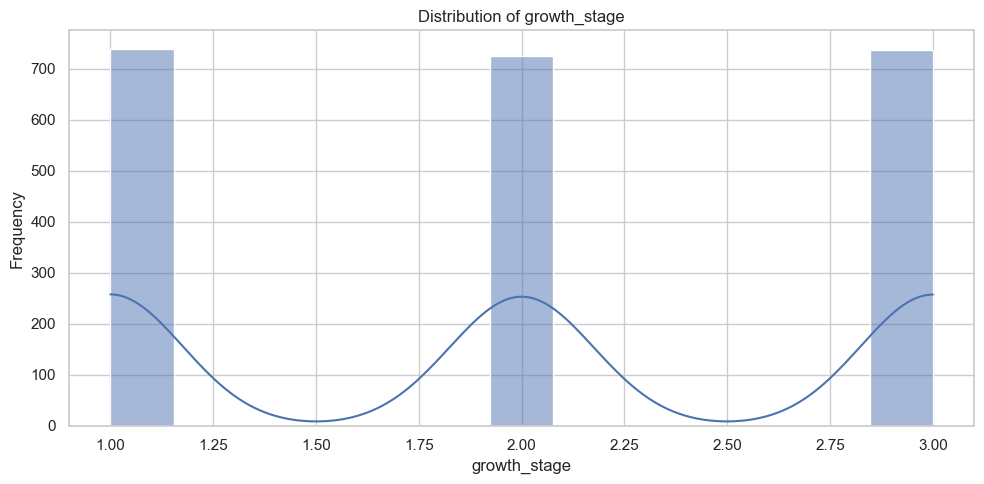

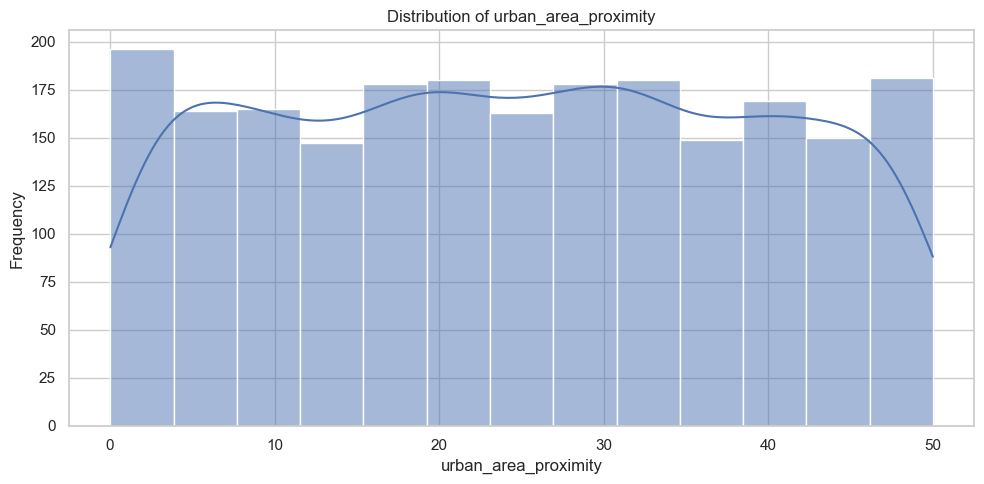

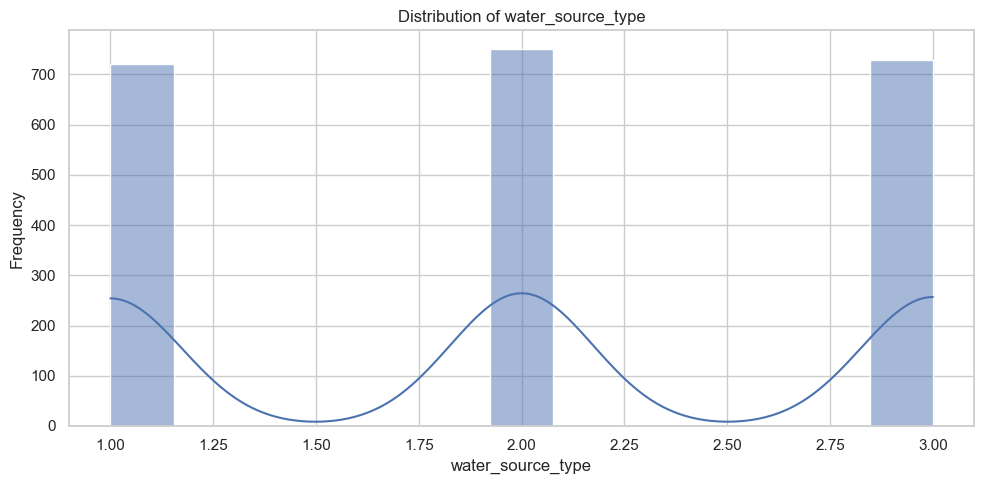

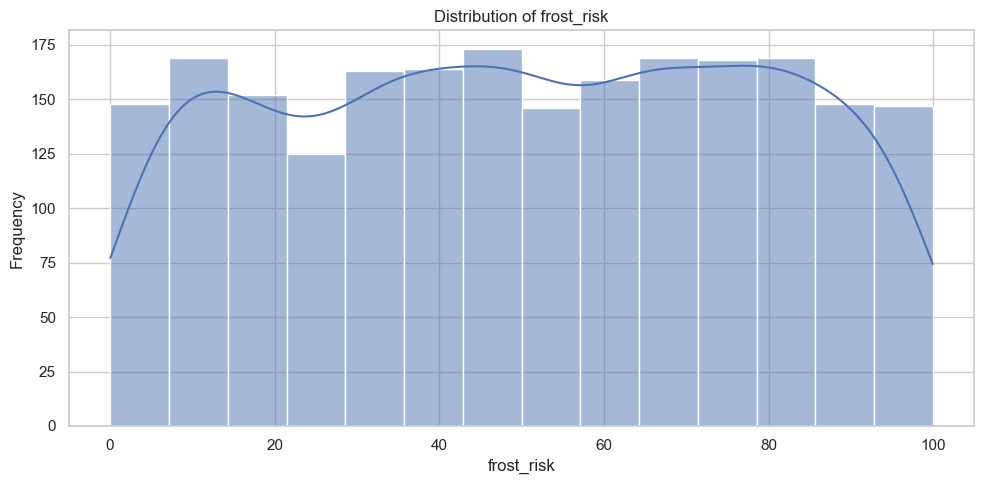

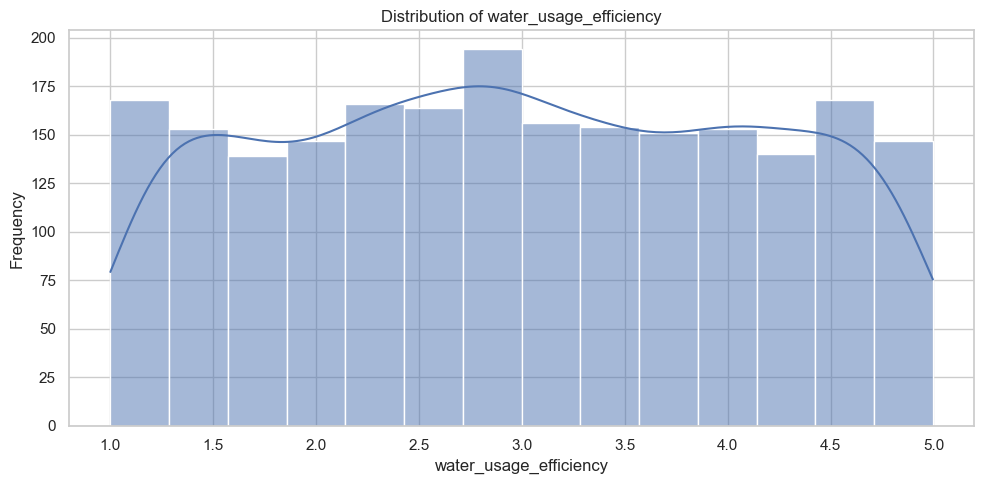

In [29]:
for column in crop_numeric:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        crop_clean[column],
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

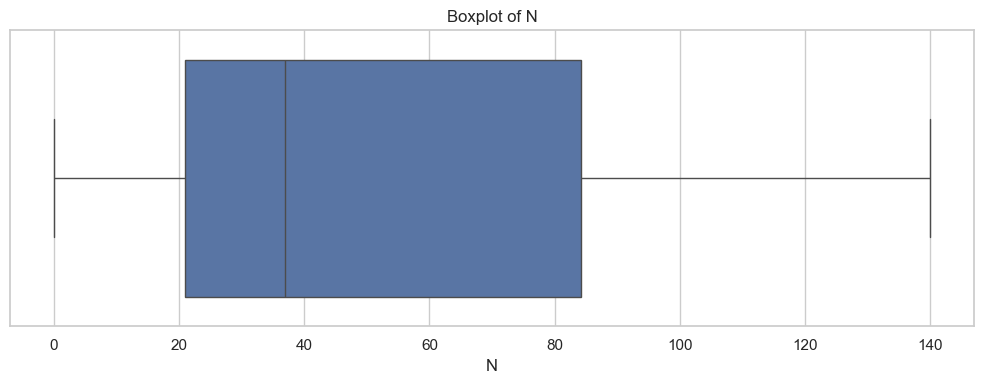

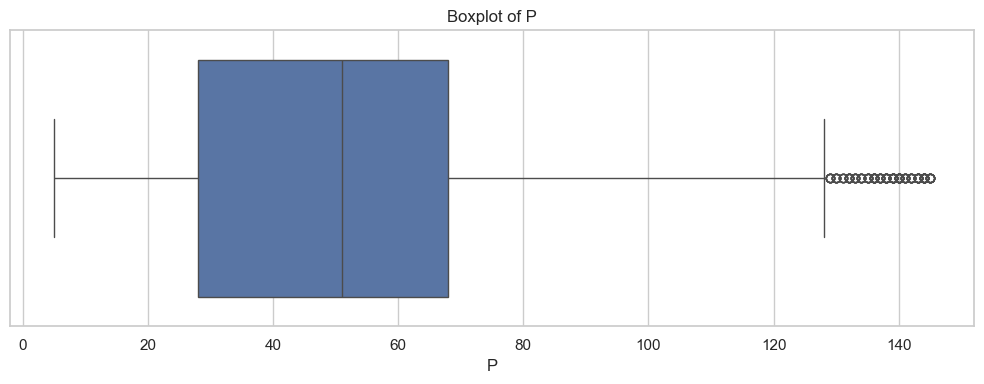

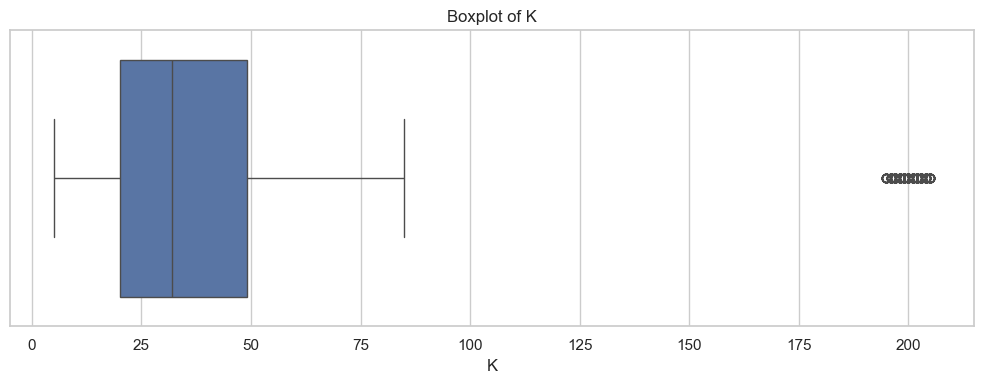

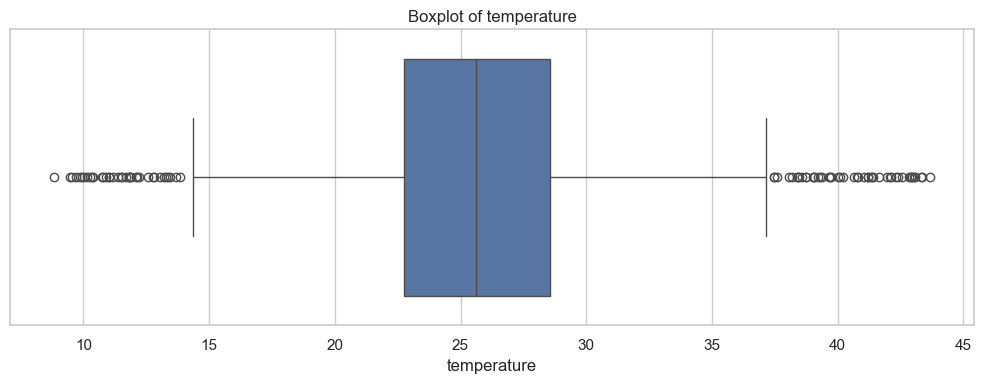

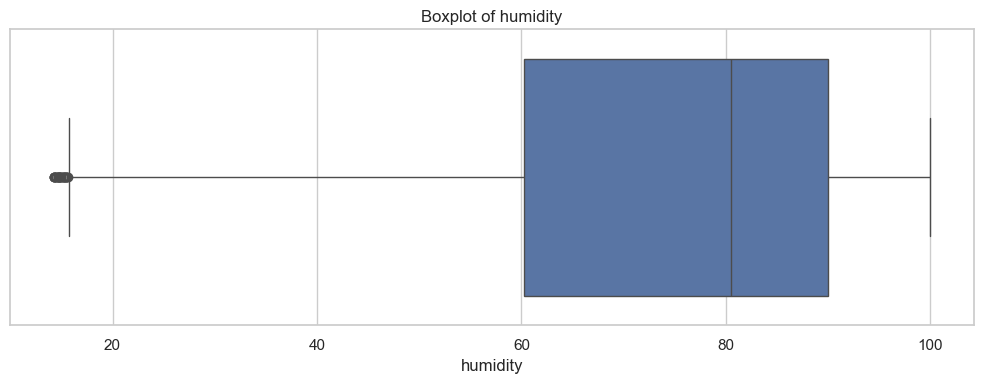

...

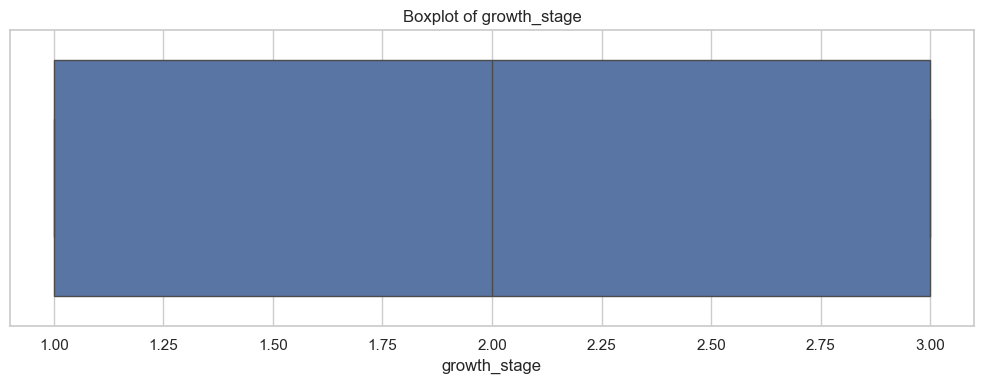

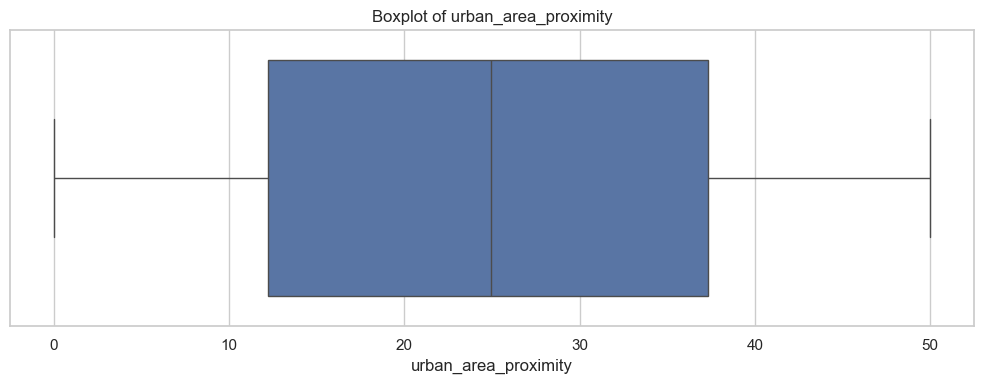

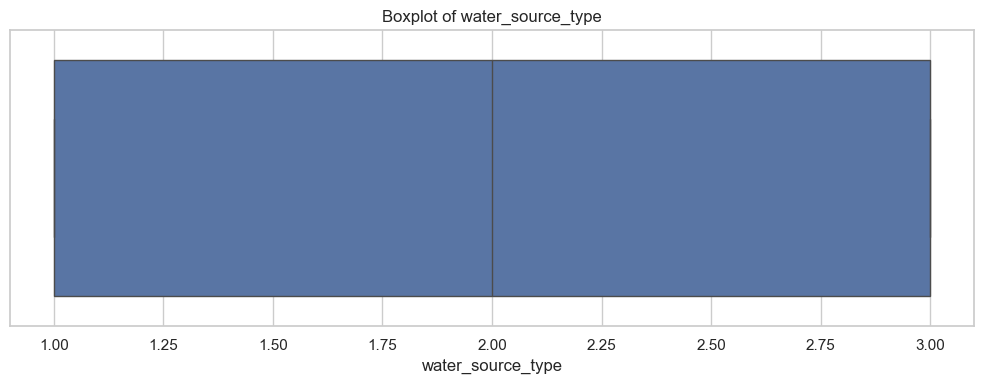

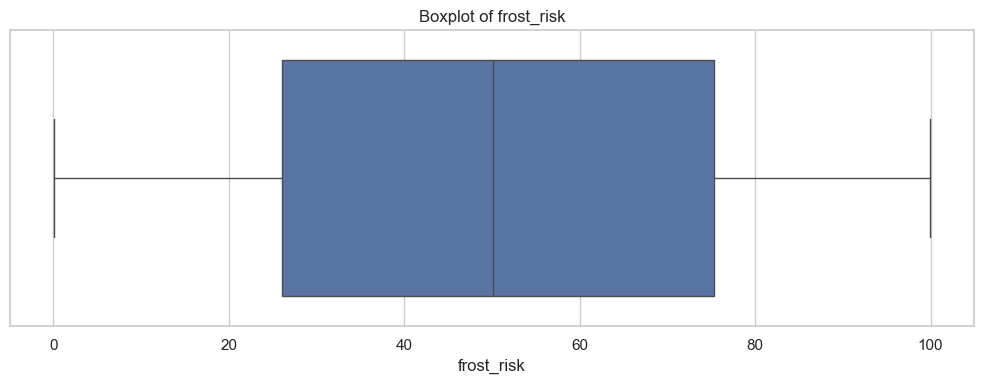

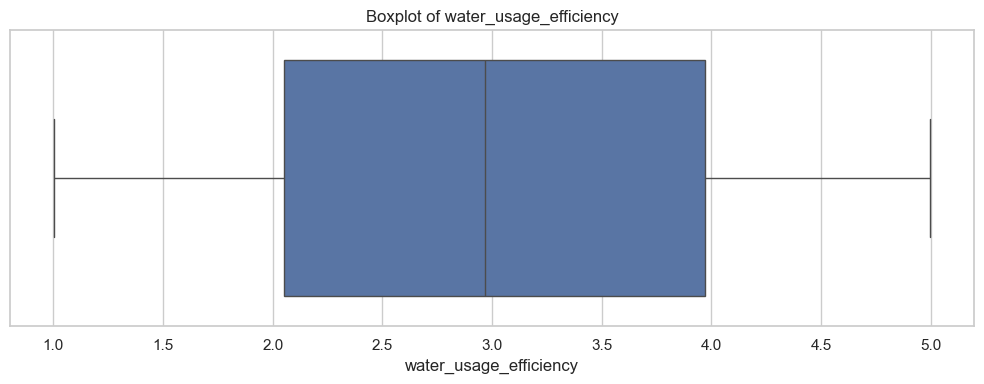

In [30]:
for column in crop_numeric:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=crop_clean[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [31]:
crop_numeric_summary = pd.DataFrame({
    "Mean": crop_clean[crop_numeric].mean(),
    "Median": crop_clean[crop_numeric].median(),
    "Std": crop_clean[crop_numeric].std(),
    "Min": crop_clean[crop_numeric].min(),
    "Max": crop_clean[crop_numeric].max(),
    "Skewness": crop_clean[crop_numeric].skew(),
    "Unique Values": crop_clean[crop_numeric].nunique()
})

display(crop_numeric_summary)

,Mean,Median,Std,Min,Max,Skewness,Unique Values
N,50.551818,37.000000,36.917334,0.000000,140.000000,0.509721,137
P,53.362727,51.000000,32.985883,5.000000,145.000000,1.010773,117
K,48.149091,32.000000,50.647931,5.000000,205.000000,2.375167,73
temperature,25.616244,25.598693,5.063749,8.825675,43.675493,0.184933,2200
humidity,71.481779,80.473146,22.263812,14.258040,99.981876,-1.091708,2200
ph,6.469480,6.425045,0.773938,3.504752,9.935091,0.283929,2200
rainfall,103.463655,94.867624,54.958389,20.211267,298.560117,0.965756,2200
soil_moisture,20.151388,20.088481,5.793720,10.024260,29.997860,-0.017638,2200
soil_type,1.991364,2.000000,0.812263,1.000000,3.000000,0.015790,3
sunlight_exposure,8.570609,8.609968,1.999382,5.000710,11.991041,-0.060095,2200


In [32]:
crop_numeric_summary = pd.DataFrame({
    "Mean": crop_clean[crop_numeric].mean(),
    "Median": crop_clean[crop_numeric].median(),
    "Std": crop_clean[crop_numeric].std(),
    "Min": crop_clean[crop_numeric].min(),
    "Max": crop_clean[crop_numeric].max(),
    "Skewness": crop_clean[crop_numeric].skew(),
    "Unique Values": crop_clean[crop_numeric].nunique()
})

display(crop_numeric_summary)

,Mean,Median,Std,Min,Max,Skewness,Unique Values
N,50.551818,37.000000,36.917334,0.000000,140.000000,0.509721,137
P,53.362727,51.000000,32.985883,5.000000,145.000000,1.010773,117
K,48.149091,32.000000,50.647931,5.000000,205.000000,2.375167,73
temperature,25.616244,25.598693,5.063749,8.825675,43.675493,0.184933,2200
humidity,71.481779,80.473146,22.263812,14.258040,99.981876,-1.091708,2200
ph,6.469480,6.425045,0.773938,3.504752,9.935091,0.283929,2200
rainfall,103.463655,94.867624,54.958389,20.211267,298.560117,0.965756,2200
soil_moisture,20.151388,20.088481,5.793720,10.024260,29.997860,-0.017638,2200
soil_type,1.991364,2.000000,0.812263,1.000000,3.000000,0.015790,3
sunlight_exposure,8.570609,8.609968,1.999382,5.000710,11.991041,-0.060095,2200


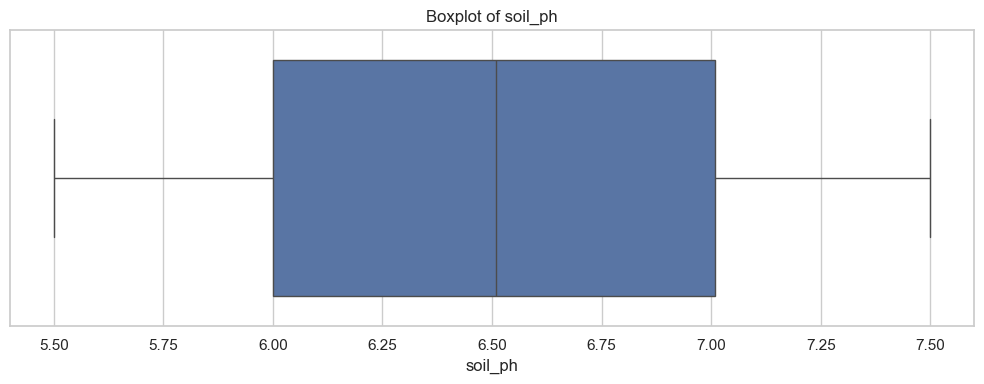

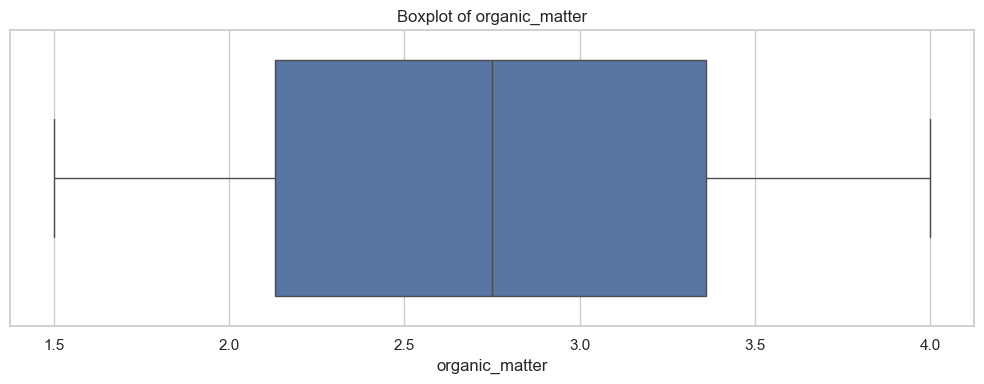

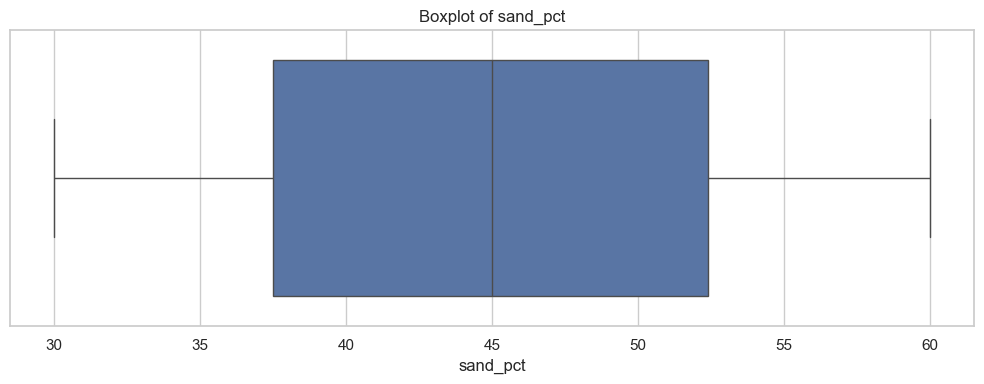

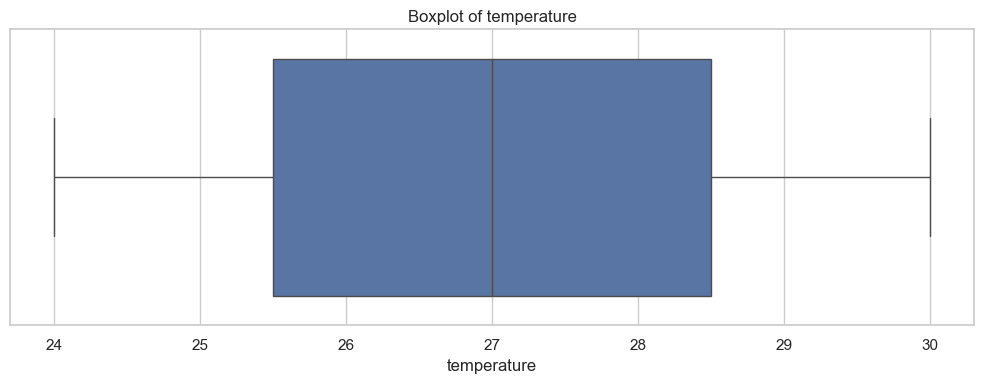

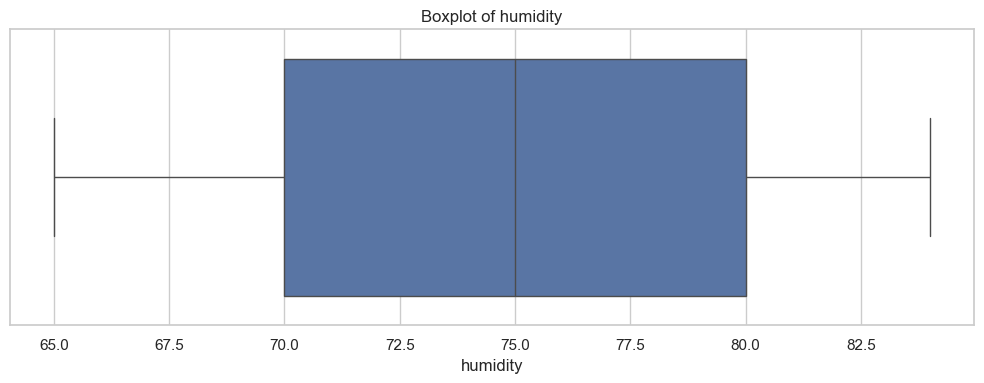

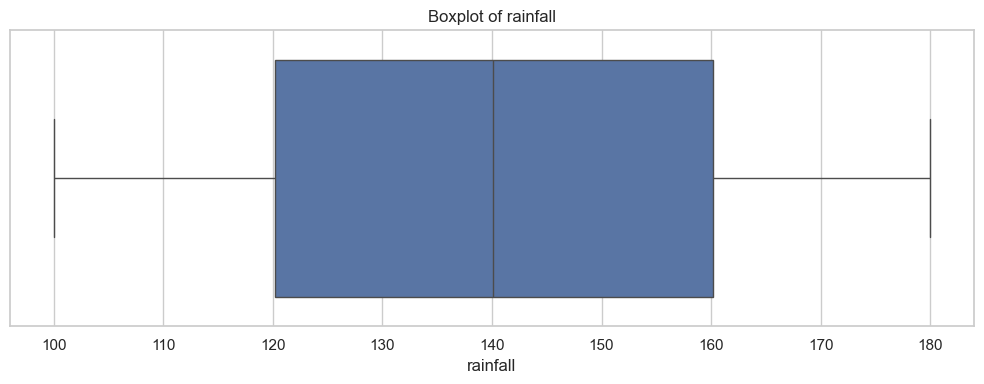

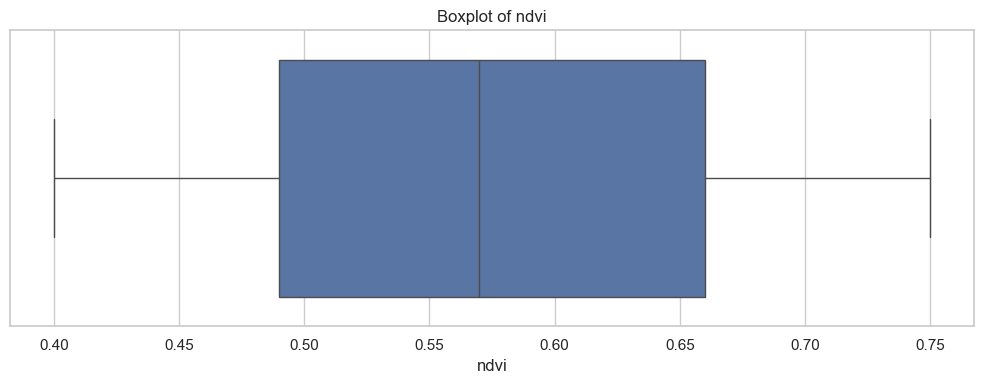

In [35]:
for column in yield_numeric:

    if column == yield_target:
        continue

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=train_clean[column]
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [34]:
yield_numeric = train_clean.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical columns:")
print(yield_numeric)

Numerical columns:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']



COLUMN: label
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


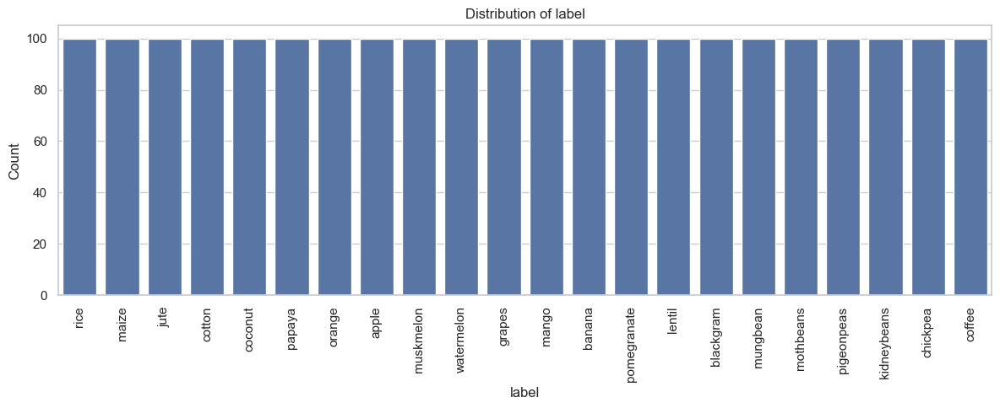

In [36]:
for column in crop_categorical:

    print("\n" + "=" * 60)
    print("COLUMN:", column)
    print("=" * 60)

    print(crop_clean[column].value_counts())

    plt.figure(figsize=(12, 5))

    order = crop_clean[column].value_counts().index

    sns.countplot(
        data=crop_clean,
        x=column,
        order=order
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()

In [37]:
yield_categorical = train_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Categorical columns:")
print(yield_categorical)


Categorical columns:
['field_id']


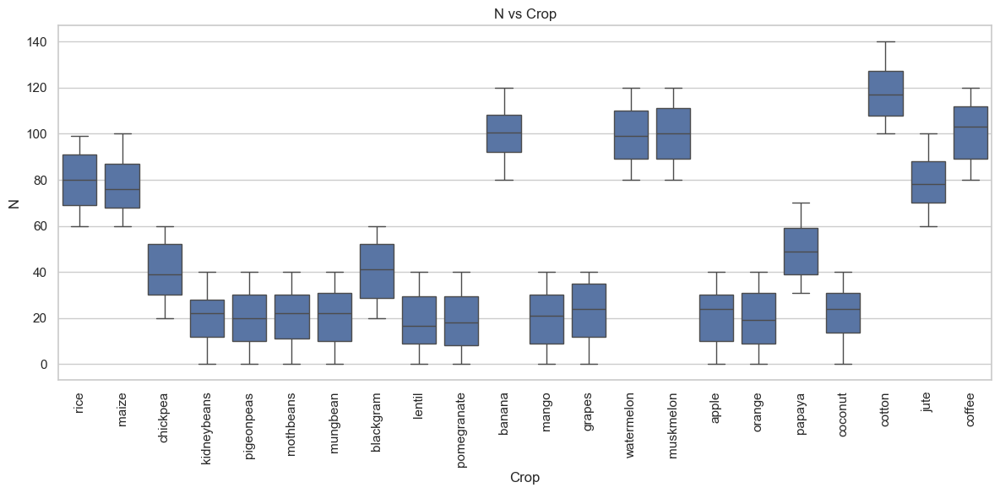

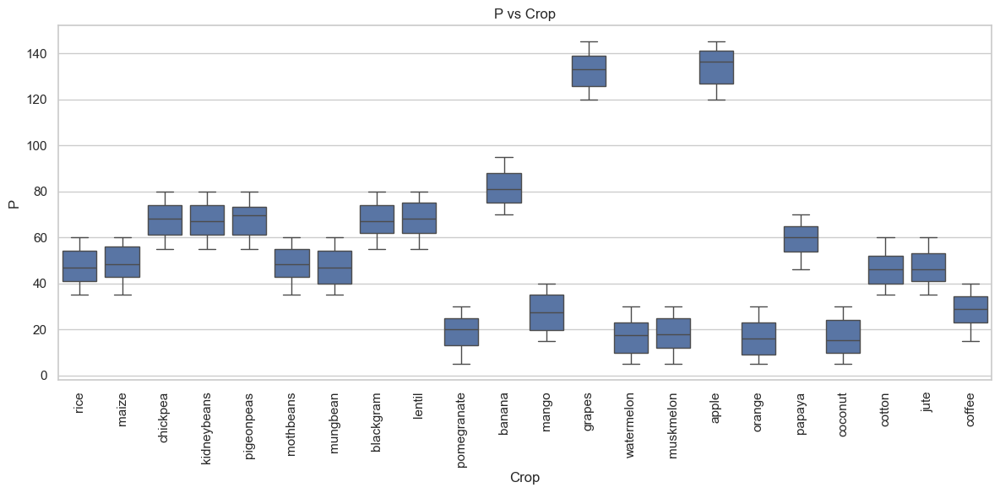

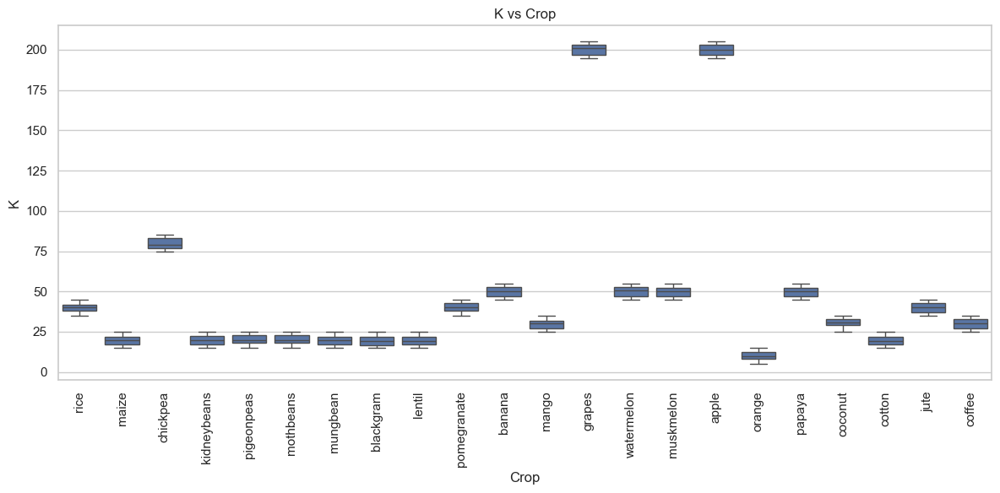

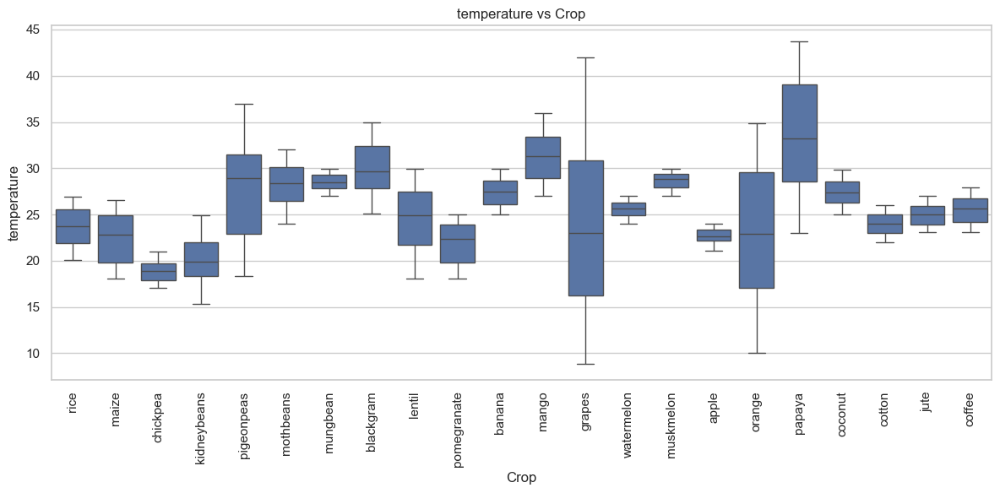

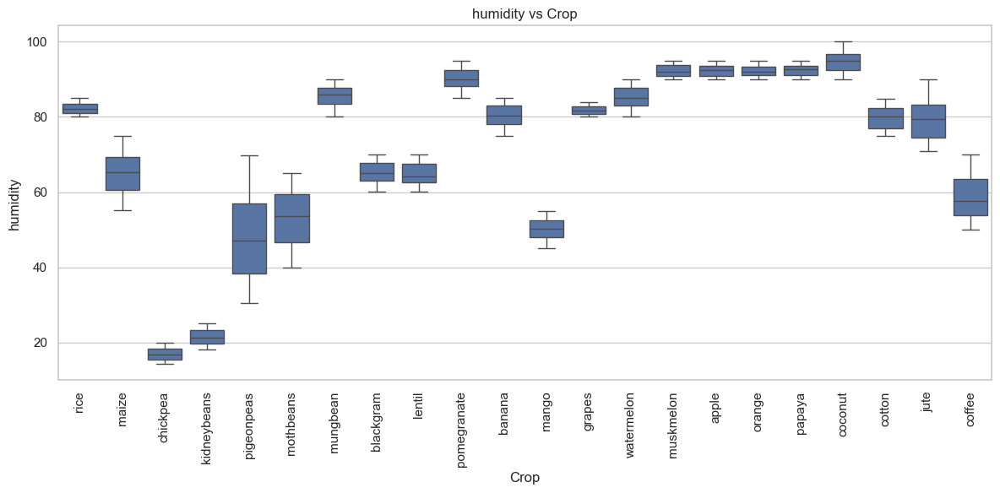

...

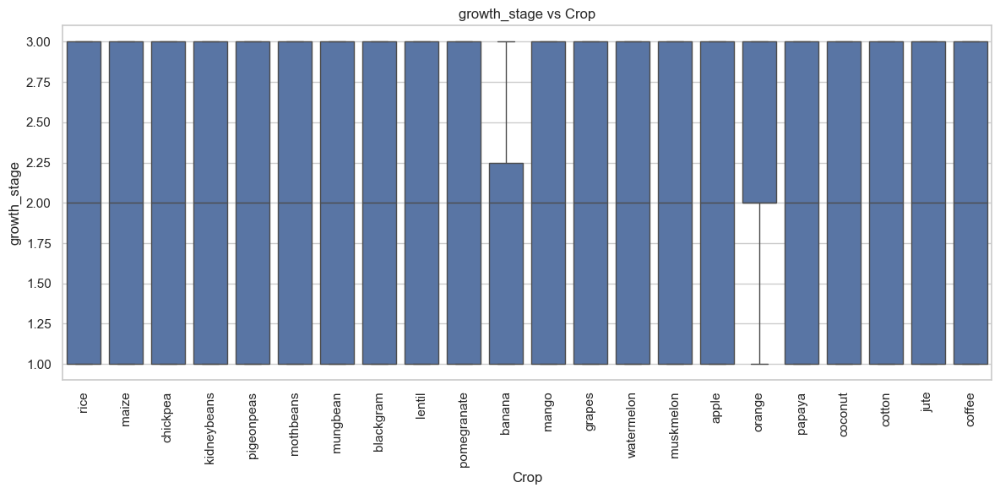

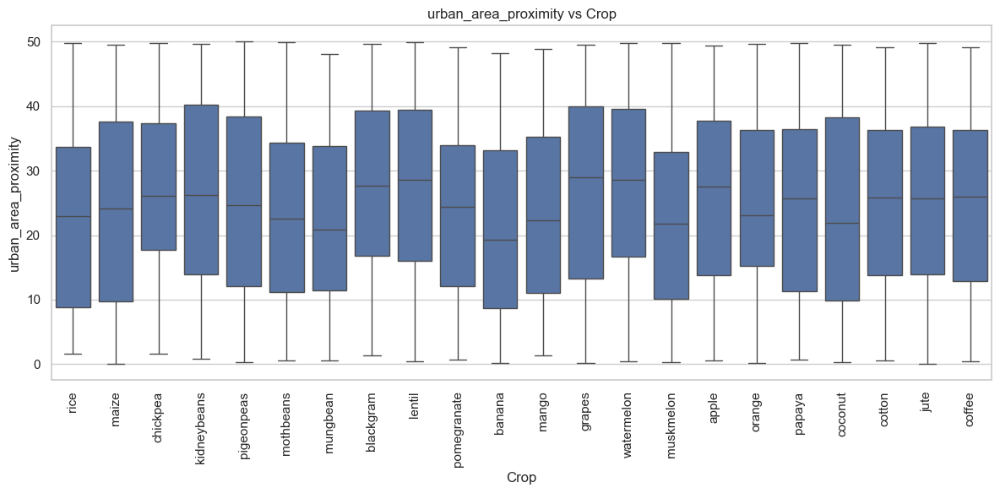

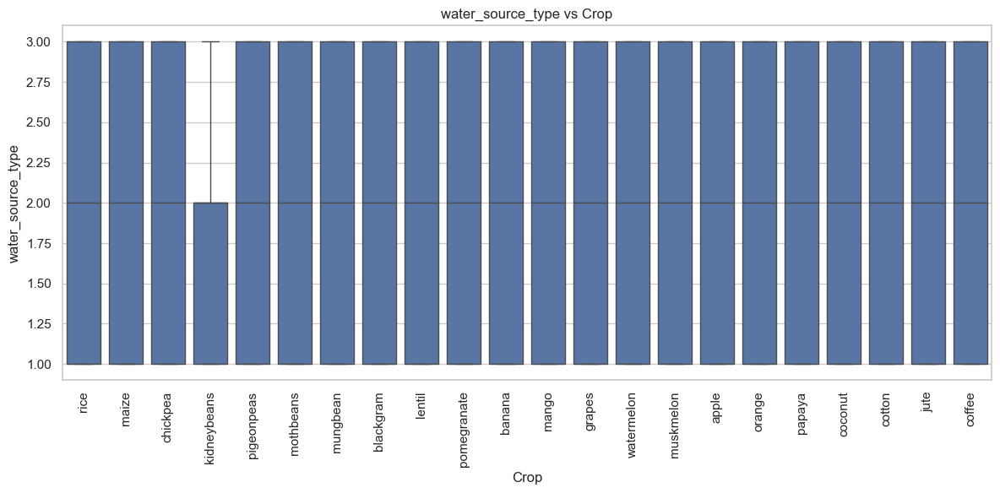

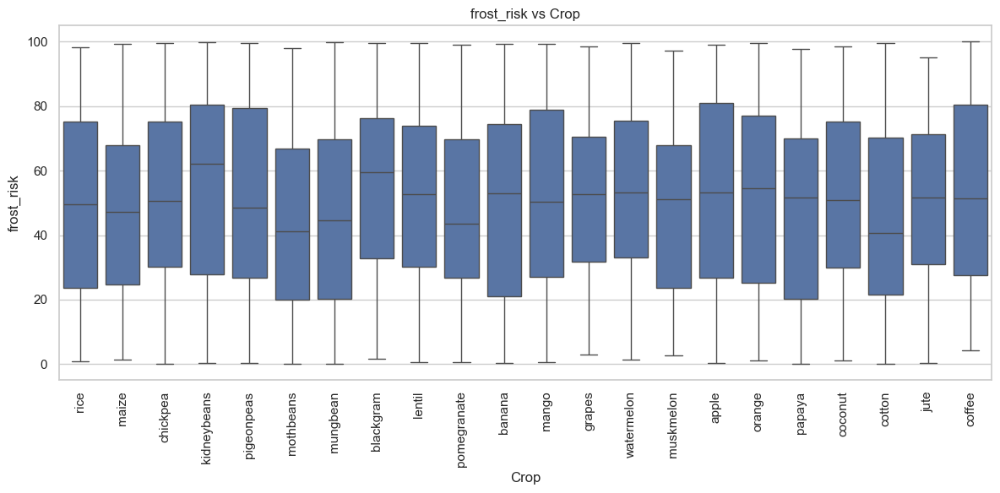

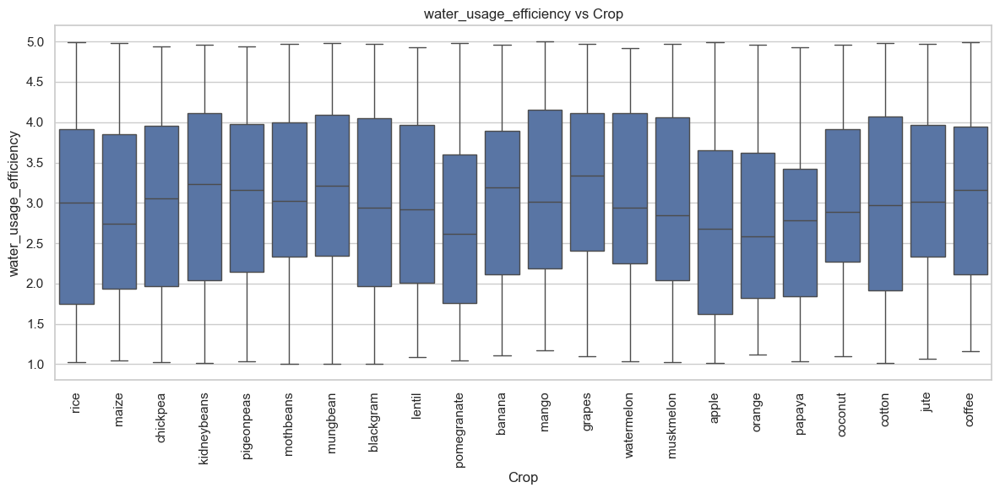

In [38]:
for column in crop_numeric:

    if column == crop_target:
        continue

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=crop_clean,
        x=crop_target,
        y=column
    )

    plt.title(f"{column} vs Crop")
    plt.xlabel("Crop")
    plt.ylabel(column)

    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()

In [39]:
crop_means = crop_clean.groupby(crop_target)[crop_numeric].mean()

display(crop_means)

,N,P,K,temperature,humidity,ph,rainfall,soil_moisture,soil_type,sunlight_exposure,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
label,,,,,,,,,,,,,,,,,,,,,
apple,20.80,134.22,199.89,22.630942,92.333383,5.929663,112.654779,21.222483,2.02,8.785265,...,5.144635,3.47,11.815561,54.333152,131.446035,1.83,26.195746,2.07,53.520342,2.768054
banana,100.23,82.01,50.05,27.376798,80.358123,5.983893,104.626980,20.428229,2.12,8.767570,...,5.828838,3.48,12.182723,51.456433,122.278745,1.94,21.398776,2.04,49.668979,3.037307
blackgram,40.02,67.47,19.24,29.973340,65.118426,7.133952,67.884151,20.875557,1.78,8.433782,...,5.392699,3.64,12.324180,45.487475,120.951328,2.09,27.255182,2.04,54.566498,2.973382
chickpea,40.09,67.79,79.92,18.872847,16.860439,7.336957,80.058977,20.242123,2.05,8.579312,...,5.511668,3.85,12.860031,50.662786,119.444731,2.03,26.892330,2.08,51.350214,2.987893
coconut,21.98,16.93,30.59,27.409892,94.844272,5.976562,175.686646,20.110048,2.05,8.883157,...,5.897110,3.48,13.205836,48.764094,128.853262,1.99,23.695625,1.97,51.524463,3.035609
coffee,101.20,28.74,29.94,25.540477,58.869846,6.790308,158.066295,19.940561,2.03,8.331250,...,5.526470,3.56,12.905832,42.331670,126.193427,2.01,24.582663,2.03,53.064990,3.048020
cotton,117.77,46.24,19.56,23.988958,79.843474,6.912675,80.398043,20.224024,1.97,8.653204,...,5.723582,3.62,12.881850,50.548912,126.777473,2.05,24.941249,1.92,44.634085,2.976705
grapes,23.18,132.53,200.11,23.849575,81.875228,6.025937,69.611829,19.620926,2.03,8.476200,...,5.380215,3.54,11.901235,45.863486,127.299475,2.10,26.951674,1.95,51.879953,3.223418
jute,78.40,46.86,39.99,24.958376,79.639864,6.732778,174.792798,18.665502,2.12,8.375210,...,5.392349,3.48,11.888416,53.487384,125.968154,1.89,25.324355,1.99,50.127714,3.112507


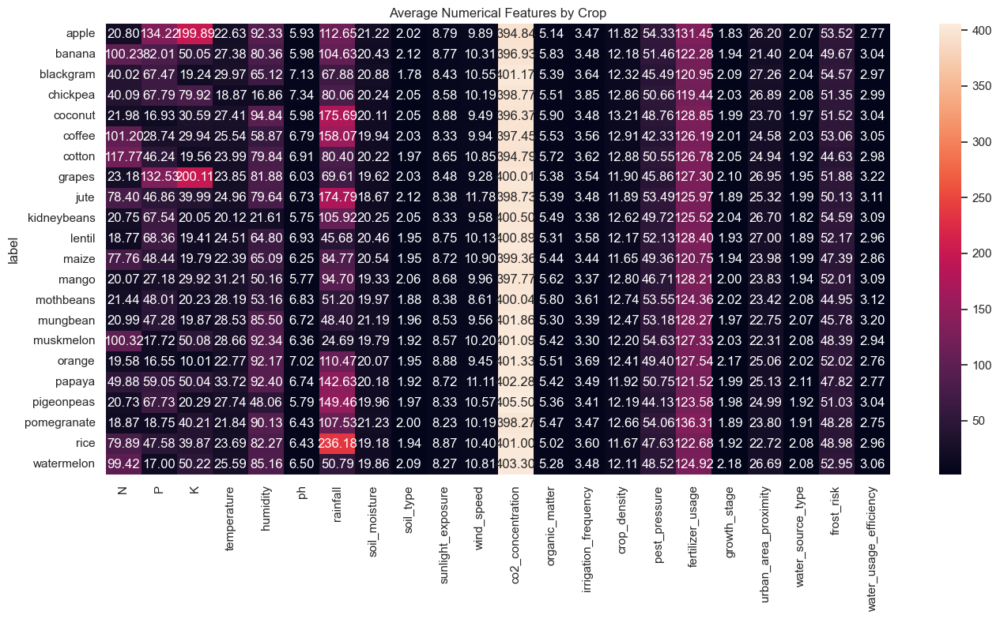

In [40]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    crop_means,
    annot=True,
    fmt=".2f"
)

plt.title("Average Numerical Features by Crop")

plt.tight_layout()
plt.show()

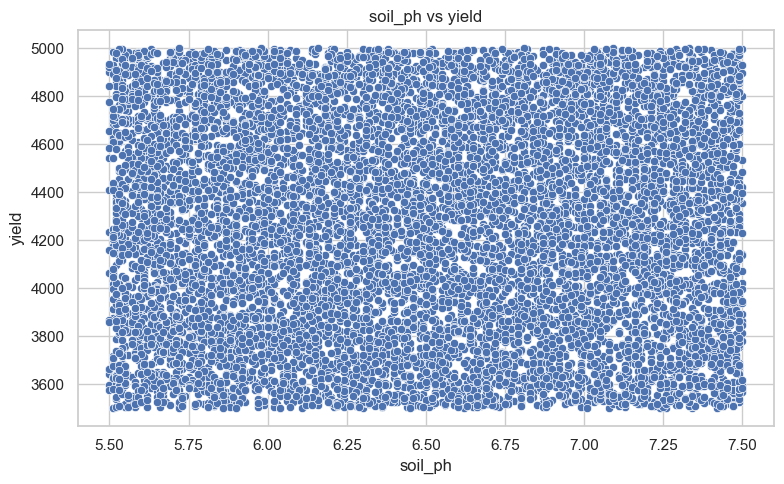

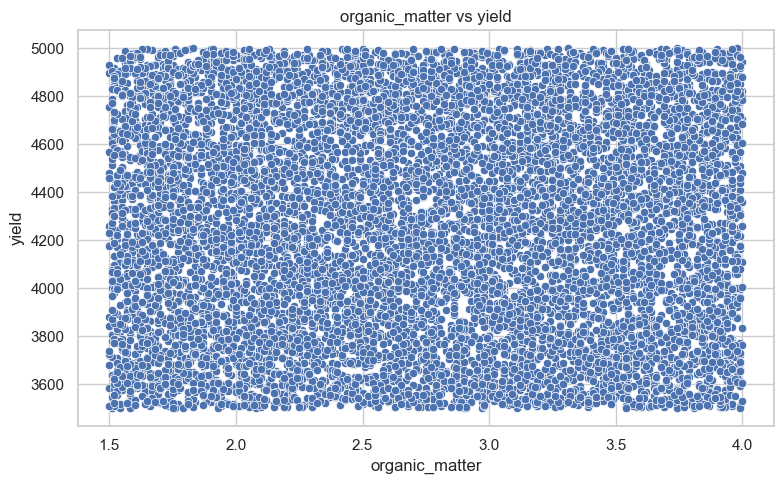

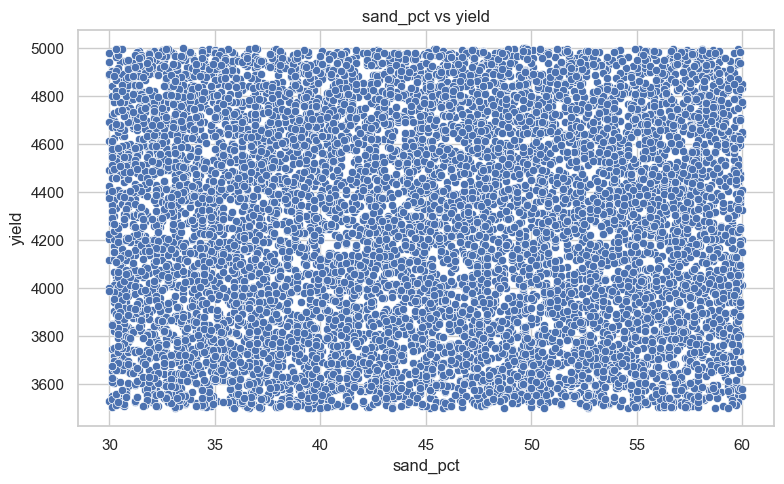

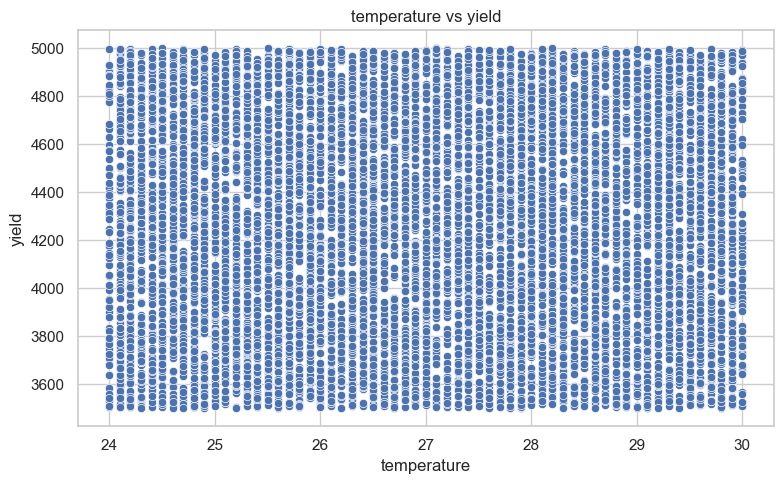

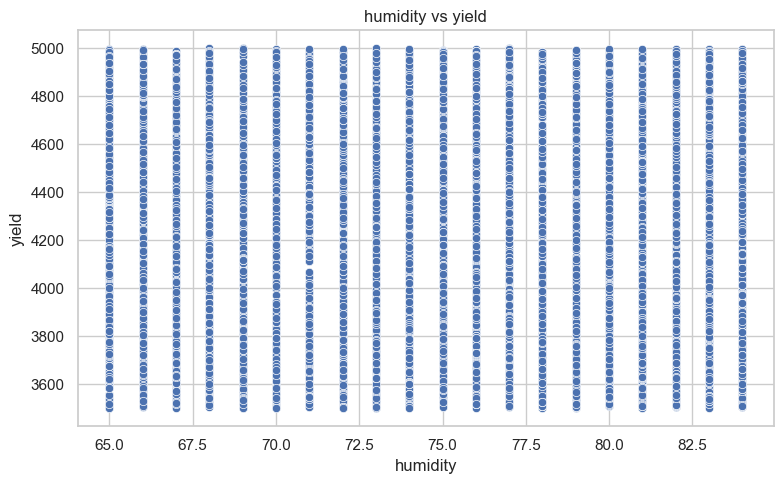

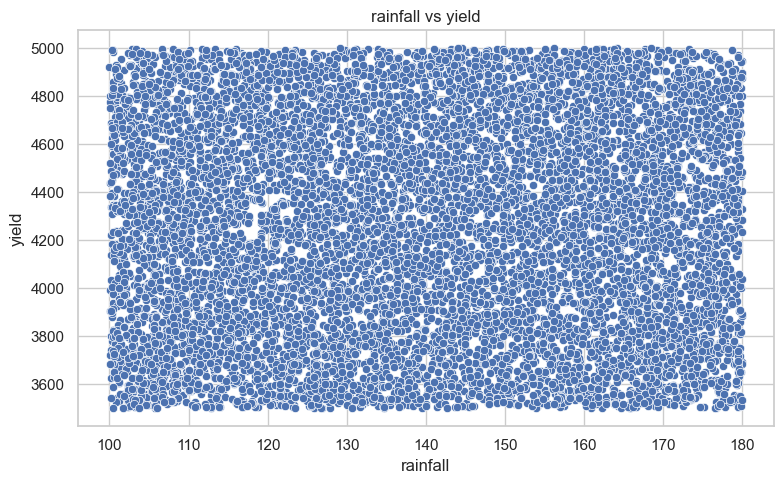

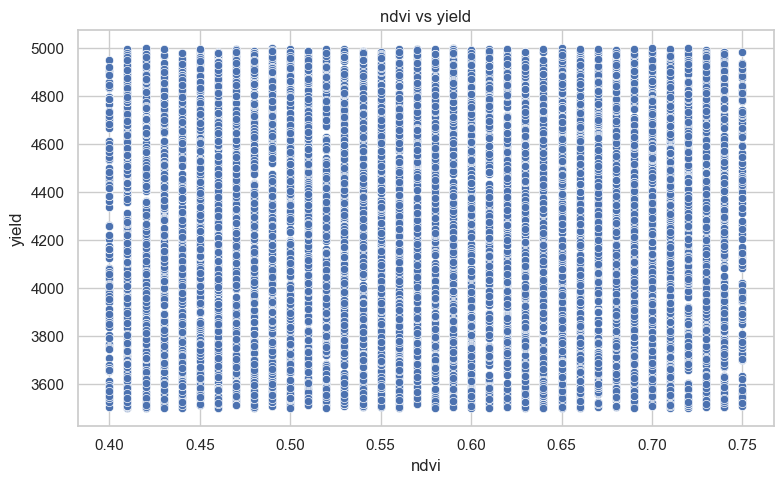

In [41]:
for column in yield_numeric:

    if column == yield_target:
        continue

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=train_clean,
        x=column,
        y=yield_target
    )

    plt.title(f"{column} vs {yield_target}")
    plt.xlabel(column)
    plt.ylabel(yield_target)

    plt.tight_layout()
    plt.show()

In [42]:
crop_corr = crop_clean[crop_numeric].corr()

display(crop_corr)

,N,P,K,temperature,humidity,ph,rainfall,soil_moisture,soil_type,sunlight_exposure,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020,-0.030749,0.021026,0.005456,...,-0.000213,-0.005733,-0.012270,-0.019974,-0.023336,0.009785,-0.023980,0.020837,-0.021273,0.005164
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839,0.017027,-0.000833,0.004664,...,-0.012194,0.012399,-0.042635,0.000187,-0.008490,-0.022348,0.044838,-0.009455,0.030244,0.009272
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461,0.008116,0.023587,0.004542,...,-0.024260,0.001386,-0.035940,0.011401,0.016329,-0.017419,0.034753,0.017159,0.025110,-0.000372
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084,-0.009842,-0.015571,0.001200,...,0.015925,-0.031864,0.026098,-0.007207,0.015709,-0.002026,-0.001946,0.031165,-0.007591,0.036147
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423,0.010933,-0.012640,0.035394,...,-0.012039,-0.016798,-0.032880,0.032015,0.033408,-0.009744,-0.041271,0.033118,-0.024591,-0.043027
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069,-0.023978,-0.020061,-0.008046,...,-0.010069,0.028987,0.002701,0.009845,-0.019893,-0.003723,0.043606,0.036664,-0.003499,-0.030026
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000,-0.048593,0.012959,0.016778,...,0.005035,0.002745,-0.005506,-0.031953,-0.011299,-0.035767,-0.022371,-0.001614,0.004942,-0.010738
soil_moisture,-0.030749,0.017027,0.008116,-0.009842,0.010933,-0.023978,-0.048593,1.000000,0.001269,0.006502,...,0.023771,-0.044011,0.005281,0.010169,-0.000946,0.002546,0.000720,-0.015919,0.012678,0.005135
soil_type,0.021026,-0.000833,0.023587,-0.015571,-0.012640,-0.020061,0.012959,0.001269,1.000000,-0.006840,...,-0.004594,0.026638,0.029293,-0.012971,-0.006542,0.024603,-0.008871,-0.019257,-0.034281,-0.001946
sunlight_exposure,0.005456,0.004664,0.004542,0.001200,0.035394,-0.008046,0.016778,0.006502,-0.006840,1.000000,...,0.002313,0.004463,0.028616,0.016590,0.015251,0.042288,-0.003850,-0.017433,-0.012445,0.012438


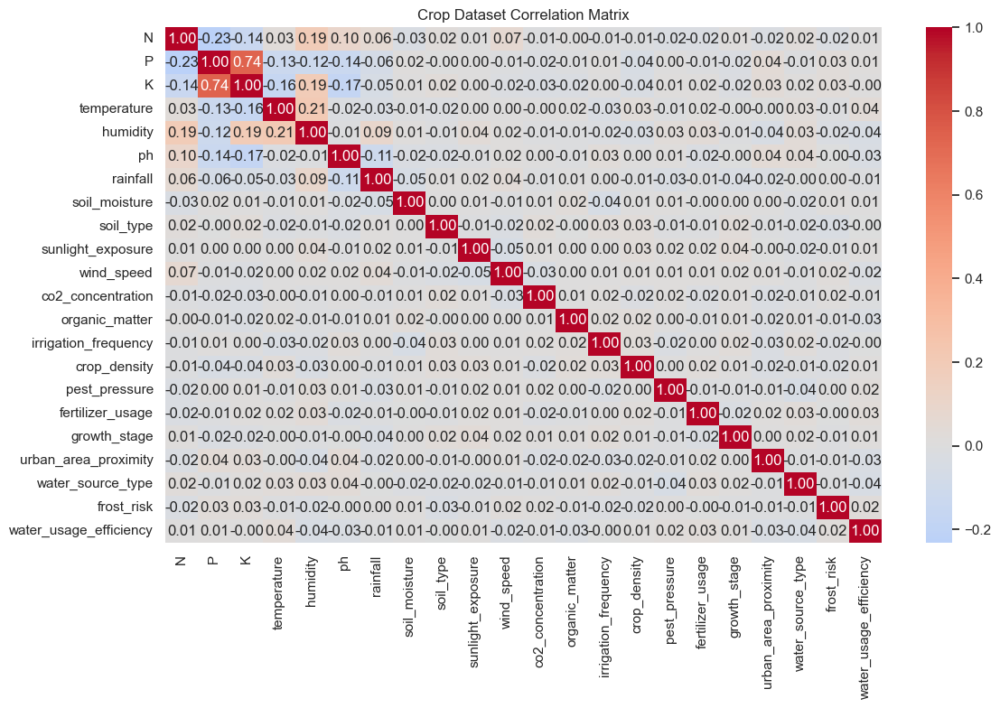

In [43]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    crop_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Crop Dataset Correlation Matrix")

plt.tight_layout()
plt.show()

In [44]:
yield_corr = train_clean[yield_numeric].corr()

display(yield_corr)

,soil_ph,organic_matter,sand_pct,temperature,humidity,rainfall,ndvi,yield
soil_ph,1.000000,-0.016595,-0.024560,-0.005485,-0.006664,-0.005365,-0.009469,0.007098
organic_matter,-0.016595,1.000000,0.000227,0.001544,-0.012198,0.007677,-0.007599,0.002207
sand_pct,-0.024560,0.000227,1.000000,0.008607,-0.004474,0.023181,-0.011729,-0.003933
temperature,-0.005485,0.001544,0.008607,1.000000,-0.013643,-0.015184,-0.009789,-0.014943
humidity,-0.006664,-0.012198,-0.004474,-0.013643,1.000000,0.003410,0.016542,0.001252
rainfall,-0.005365,0.007677,0.023181,-0.015184,0.003410,1.000000,-0.027723,0.016959
ndvi,-0.009469,-0.007599,-0.011729,-0.009789,0.016542,-0.027723,1.000000,-0.001619
yield,0.007098,0.002207,-0.003933,-0.014943,0.001252,0.016959,-0.001619,1.000000


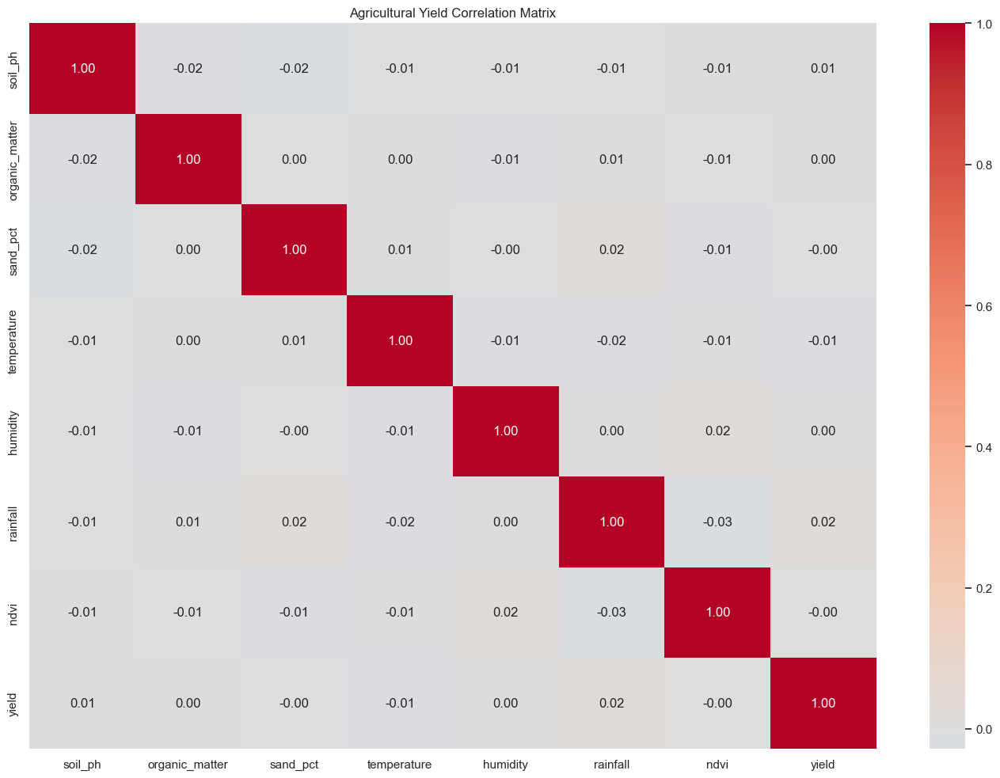

In [45]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    yield_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Agricultural Yield Correlation Matrix")

plt.tight_layout()
plt.show()

In [46]:
yield_target_corr = (
    train_clean[yield_numeric]
    .corr()[yield_target]
    .sort_values(ascending=False)
)

display(yield_target_corr)

yield             1.000000
rainfall          0.016959
soil_ph           0.007098
organic_matter    0.002207
humidity          0.001252
ndvi             -0.001619
sand_pct         -0.003933
temperature      -0.014943
Name: yield, dtype: float64

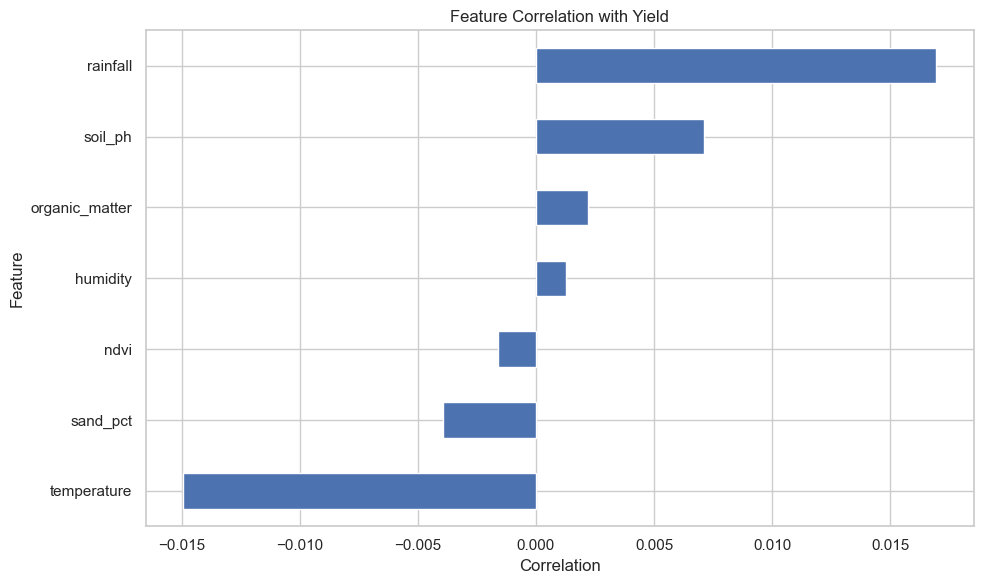

In [47]:
plt.figure(figsize=(10, 6))

yield_target_corr.drop(yield_target).sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Yield")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

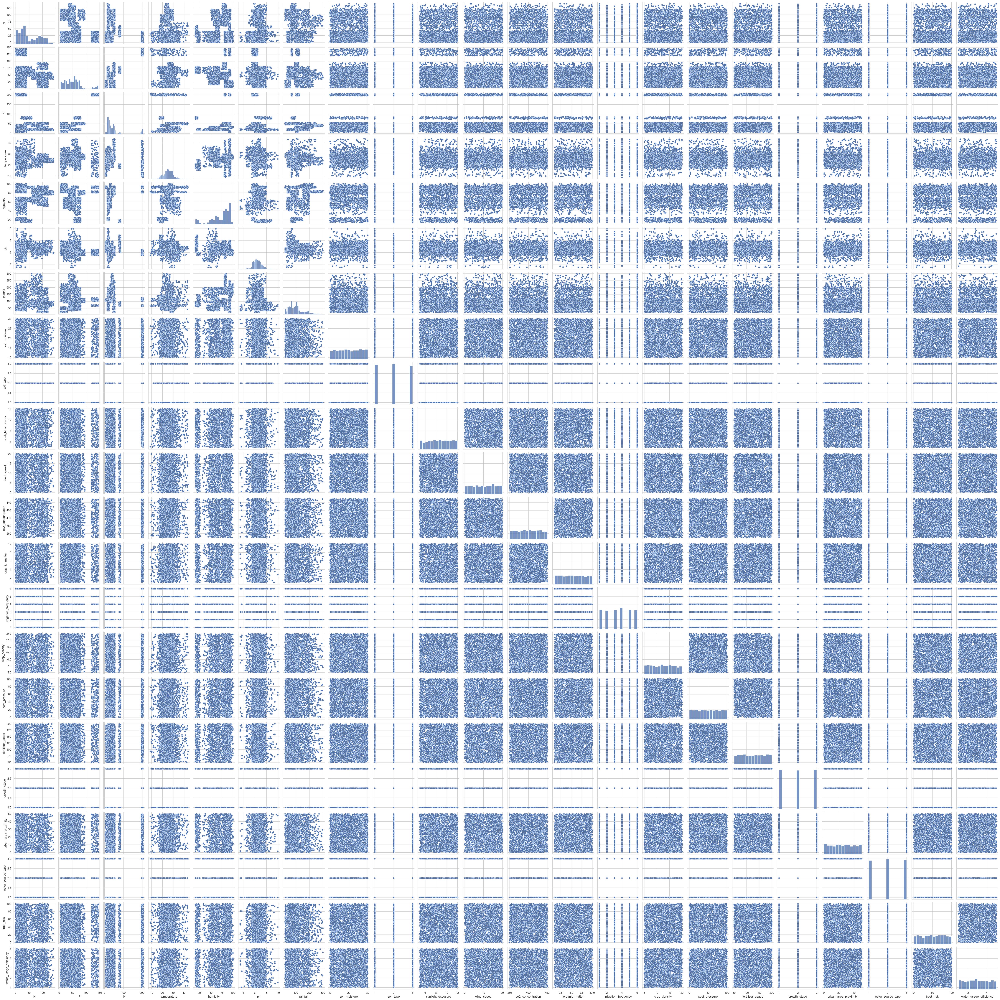

In [48]:
sns.pairplot(
    crop_clean[crop_numeric]
)

plt.show()

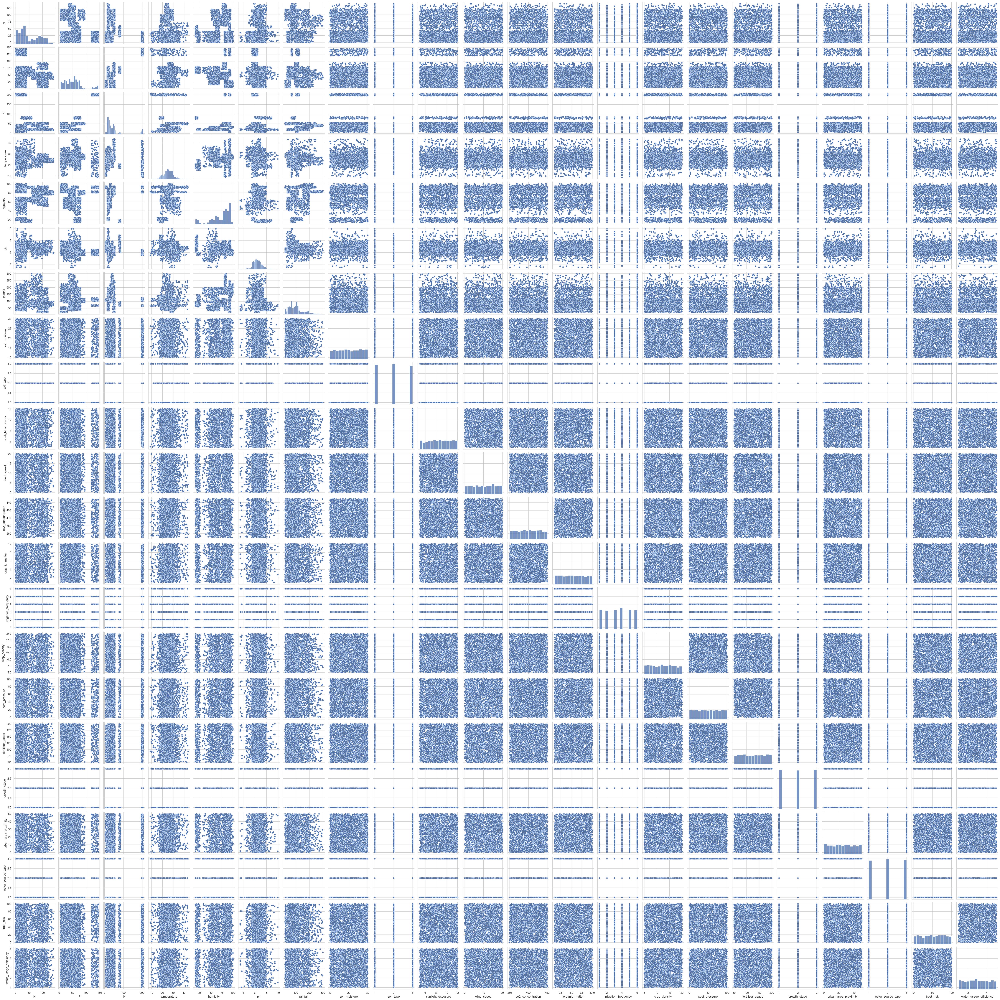

In [49]:
sns.pairplot(
    crop_clean[crop_numeric]
)

plt.show()

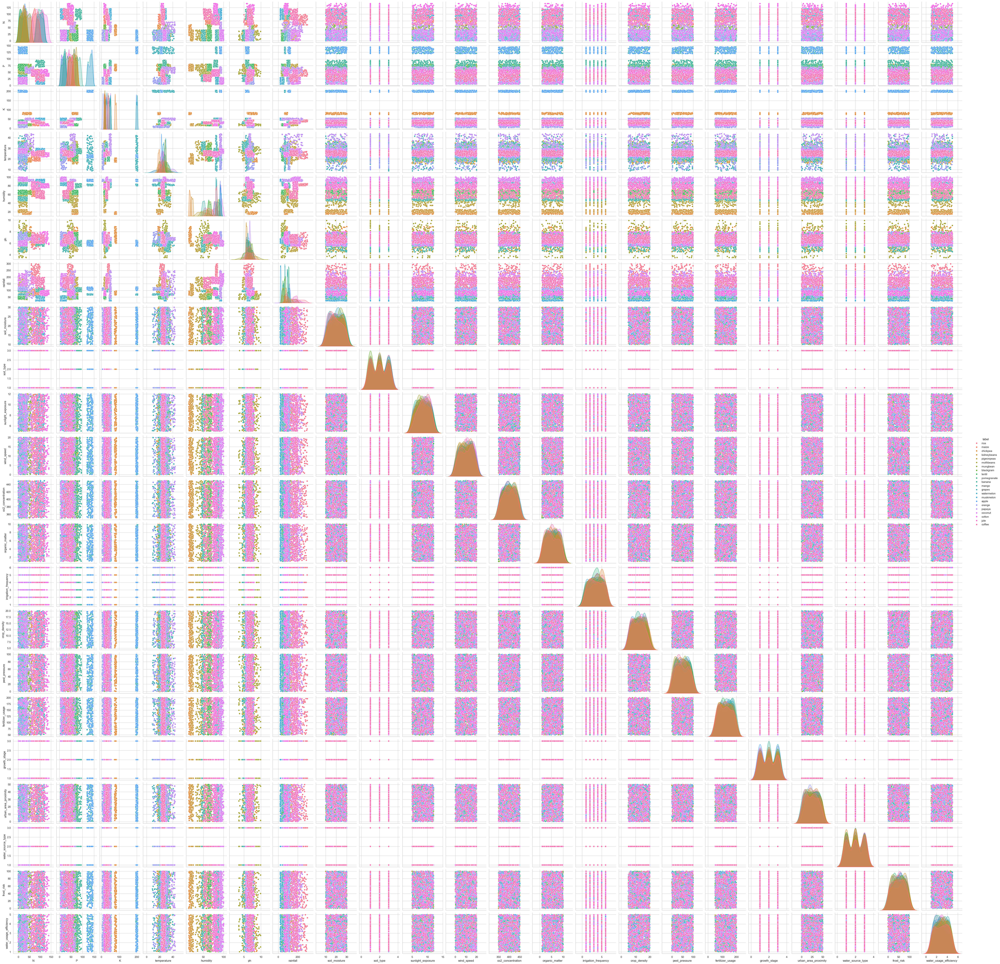

In [50]:
sns.pairplot(
    crop_clean,
    hue=crop_target,
    vars=crop_numeric
)

plt.show()

In [51]:
def outlier_summary(df, numerical_columns):

    results = []

    for column in numerical_columns:

        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        count = (
            (df[column] < lower) |
            (df[column] > upper)
        ).sum()

        percentage = (count / len(df)) * 100

        results.append({
            "Feature": column,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower Bound": lower,
            "Upper Bound": upper,
            "Outlier Count": count,
            "Outlier Percentage": percentage
        })

    return pd.DataFrame(results)

In [52]:
crop_outliers = outlier_summary(
    crop_clean,
    crop_numeric
)

display(crop_outliers)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,N,21.000000,84.250000,63.250000,-73.875000,179.125000,0,0.000000
1,P,28.000000,68.000000,40.000000,-32.000000,128.000000,138,6.272727
2,K,20.000000,49.000000,29.000000,-23.500000,92.500000,200,9.090909
3,temperature,22.769375,28.561654,5.792279,14.080956,37.250073,86,3.909091
4,humidity,60.261953,89.948771,29.686818,15.731726,134.478998,30,1.363636
5,ph,5.971693,6.923643,0.951950,4.543768,8.351567,57,2.590909
6,rainfall,64.551686,124.267508,59.715822,-25.022047,213.841241,100,4.545455
7,soil_moisture,15.179949,25.255146,10.075197,0.067154,40.367941,0,0.000000
8,soil_type,1.000000,3.000000,2.000000,-2.000000,6.000000,0,0.000000
9,sunlight_exposure,6.904620,10.220394,3.315773,1.930960,15.194054,0,0.000000


In [53]:
yield_outliers = outlier_summary(
    train_clean,
    yield_numeric
)

display(yield_outliers)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,soil_ph,6.00,7.010,1.010,4.4850,8.5250,0,0.0
1,organic_matter,2.13,3.360,1.230,0.2850,5.2050,0,0.0
2,sand_pct,37.50,52.400,14.900,15.1500,74.7500,0,0.0
3,temperature,25.50,28.500,3.000,21.0000,33.0000,0,0.0
4,humidity,70.00,80.000,10.000,55.0000,95.0000,0,0.0
5,rainfall,120.20,160.200,40.000,60.2000,220.2000,0,0.0
6,ndvi,0.49,0.660,0.170,0.2350,0.9150,0,0.0
7,yield,3868.05,4638.325,770.275,2712.6375,5793.7375,0,0.0


In [54]:
train_mean = train_clean[yield_numeric].mean()
test_mean = test_clean[yield_numeric].mean()

distribution_comparison = pd.DataFrame({
    "Train Mean": train_mean,
    "Test Mean": test_mean,
    "Difference": train_mean - test_mean
})

display(distribution_comparison)

KeyError: "['yield'] not in index"

In [55]:
train_std = train_clean[yield_numeric].std()
test_std = test_clean[yield_numeric].std()

std_comparison = pd.DataFrame({
    "Train Std": train_std,
    "Test Std": test_std,
    "Difference": train_std - test_std
})

display(std_comparison)

KeyError: "['yield'] not in index"

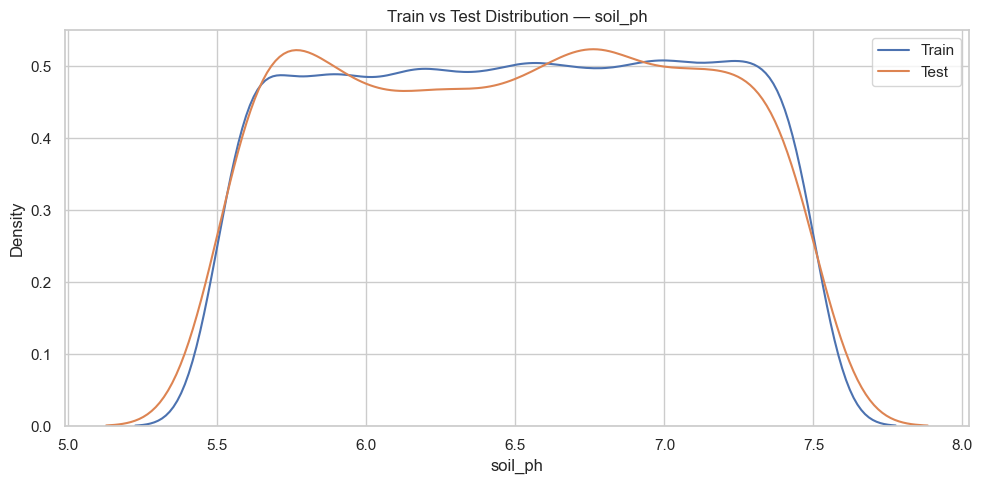

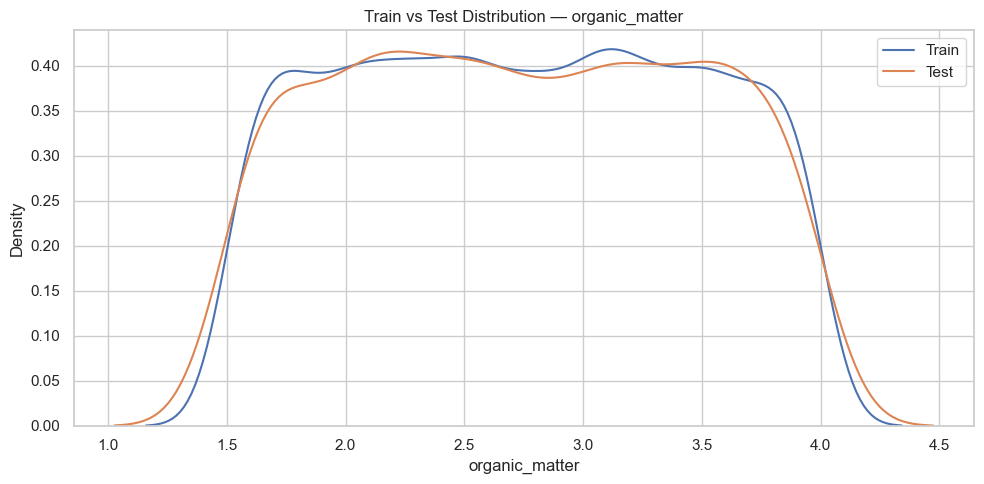

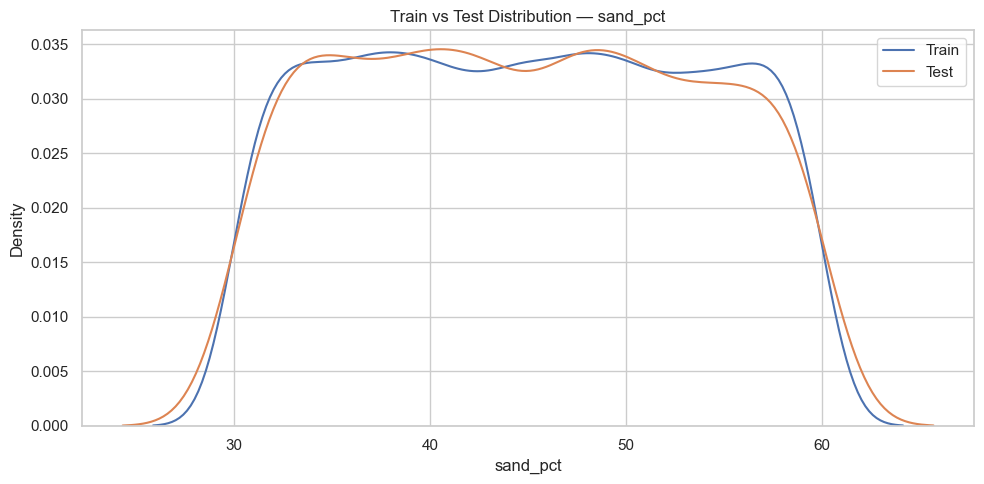

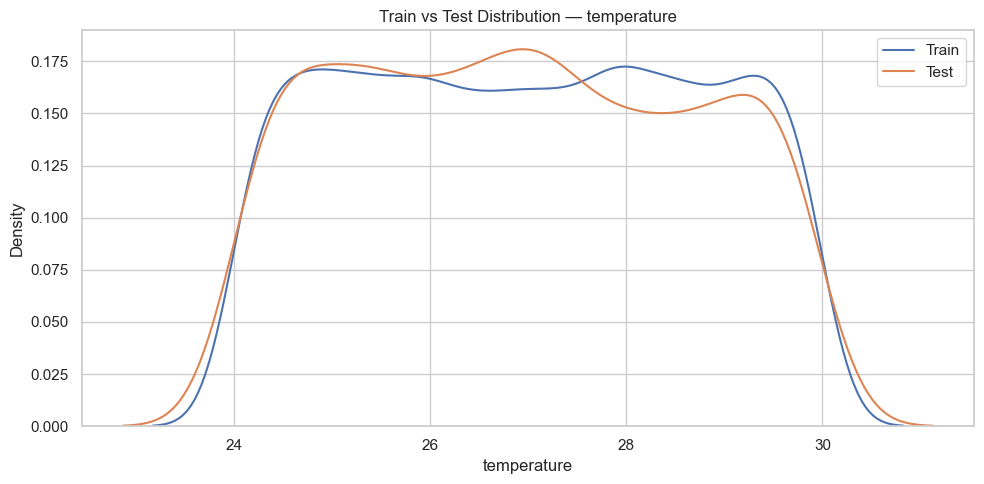

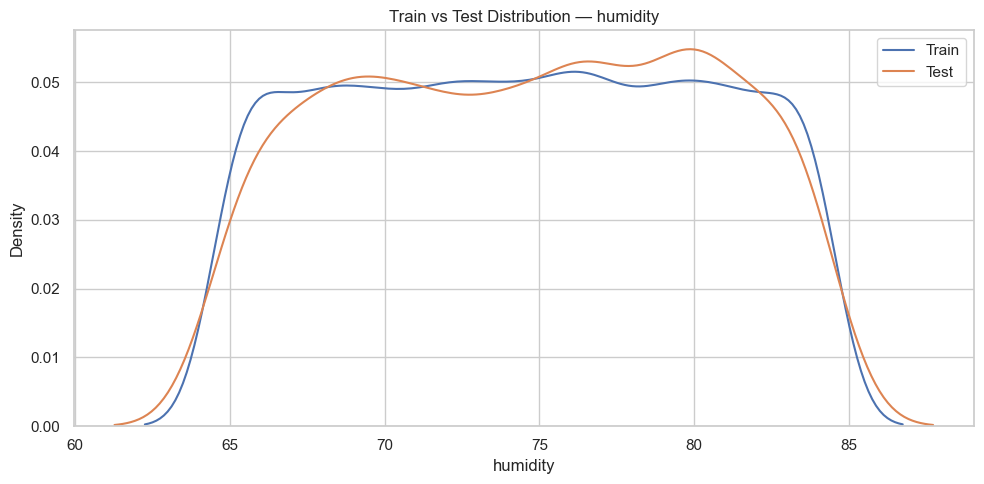

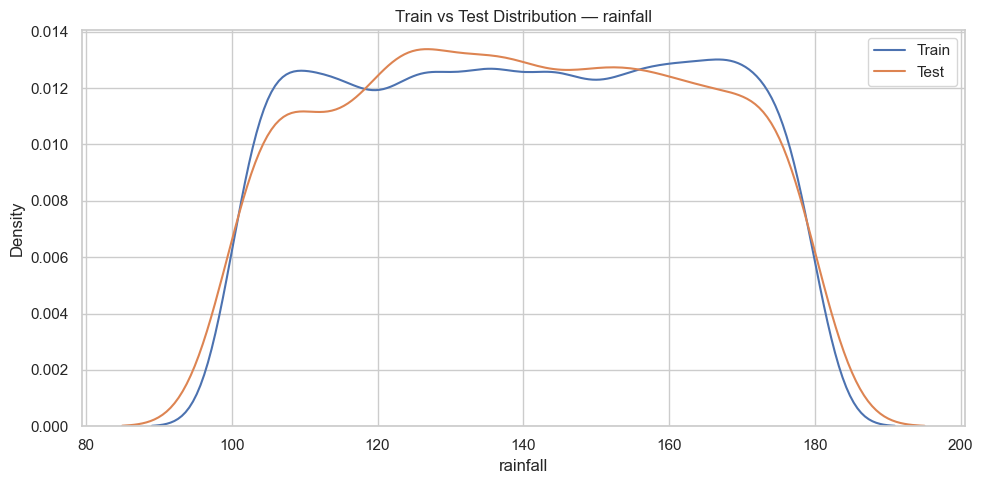

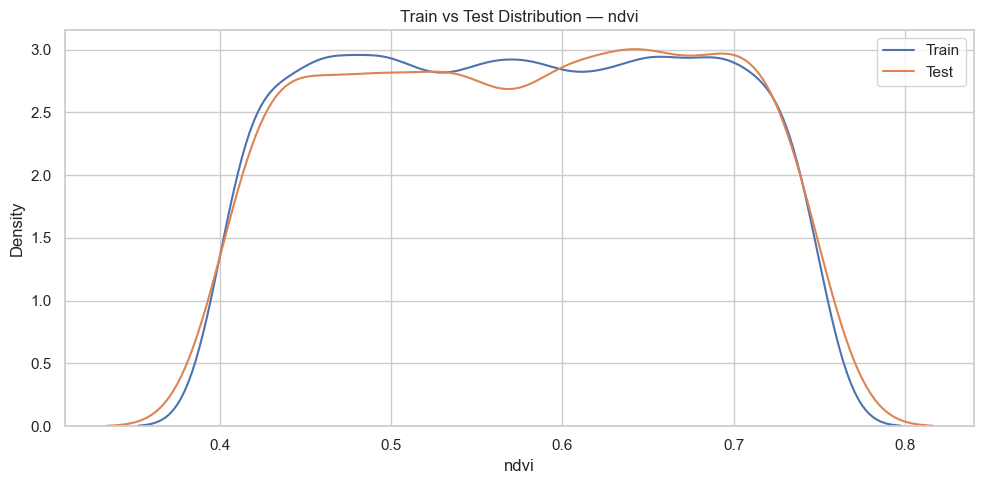

In [56]:
for column in yield_numeric:

    if column == yield_target:
        continue

    plt.figure(figsize=(10, 5))

    sns.kdeplot(
        train_clean[column],
        label="Train"
    )

    sns.kdeplot(
        test_clean[column],
        label="Test"
    )

    plt.title(f"Train vs Test Distribution — {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [57]:
import sqlite3

conn = sqlite3.connect("agriculture.db")

In [58]:
query = """
SELECT COUNT(*) AS total_rows
FROM crop_recommendation_clean;
"""

display(pd.read_sql_query(query, conn))

,total_rows
0,2200


In [59]:
query = f"""
SELECT "{crop_target}", COUNT(*) AS count
FROM crop_recommendation_clean
GROUP BY "{crop_target}"
ORDER BY count DESC;
"""

display(pd.read_sql_query(query, conn))

,label,count
0,watermelon,100
1,rice,100
2,pomegranate,100
3,pigeonpeas,100
4,papaya,100
5,orange,100
6,muskmelon,100
7,mungbean,100
8,mothbeans,100
9,mango,100


In [60]:
query = f"""
SELECT "{crop_target}", COUNT(*) AS count
FROM crop_recommendation_clean
GROUP BY "{crop_target}"
ORDER BY count DESC;
"""

display(pd.read_sql_query(query, conn))

,label,count
0,watermelon,100
1,rice,100
2,pomegranate,100
3,pigeonpeas,100
4,papaya,100
5,orange,100
6,muskmelon,100
7,mungbean,100
8,mothbeans,100
9,mango,100


In [61]:
def dataset_summary(df, name):

    print("=" * 70)
    print(name.upper())
    print("=" * 70)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    print("\nMissing Values:")
    print(df.isnull().sum().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nNumerical Columns:")
    print(df.select_dtypes(include=np.number).columns.tolist())

    print("\nCategorical Columns:")
    print(df.select_dtypes(exclude=np.number).columns.tolist())

    print("\nMemory Usage:")
    print(
        round(
            df.memory_usage(deep=True).sum() / 1024**2,
            2
        ),
        "MB"
    )

In [62]:
dataset_summary(
    crop_clean,
    "Crop Recommendation Dataset"
)

dataset_summary(
    train_clean,
    "Agri Yield Training Dataset"
)

dataset_summary(
    test_clean,
    "Agri Yield Testing Dataset"
)

CROP RECOMMENDATION DATASET
Rows: 2200
Columns: 23

Missing Values:
0

Duplicate Rows:
0

Numerical Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

Categorical Columns:
['label']

Memory Usage:
0.49 MB
AGRI YIELD TRAINING DATASET
Rows: 10000
Columns: 9

Missing Values:
0

Duplicate Rows:
0

Numerical Columns:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']

Categorical Columns:
['field_id']

Memory Usage:
1.13 MB
AGRI YIELD TESTING DATASET
Rows: 2000
Columns: 8

Missing Values:
0

Duplicate Rows:
0

Numerical Columns:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']

Categorical Columns:
['field_id

In [63]:
def numerical_profile(df):

    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns

    profile = pd.DataFrame({
        "Data Type": df[numerical_columns].dtypes,
        "Missing": df[numerical_columns].isnull().sum(),
        "Unique": df[numerical_columns].nunique(),
        "Mean": df[numerical_columns].mean(),
        "Median": df[numerical_columns].median(),
        "Std": df[numerical_columns].std(),
        "Min": df[numerical_columns].min(),
        "Max": df[numerical_columns].max(),
        "Skewness": df[numerical_columns].skew()
    })

    return profile

In [64]:
display(
    numerical_profile(crop_clean)
)

,Data Type,Missing,Unique,Mean,Median,Std,Min,Max,Skewness
N,int64,0,137,50.551818,37.000000,36.917334,0.000000,140.000000,0.509721
P,int64,0,117,53.362727,51.000000,32.985883,5.000000,145.000000,1.010773
K,int64,0,73,48.149091,32.000000,50.647931,5.000000,205.000000,2.375167
temperature,float64,0,2200,25.616244,25.598693,5.063749,8.825675,43.675493,0.184933
humidity,float64,0,2200,71.481779,80.473146,22.263812,14.258040,99.981876,-1.091708
ph,float64,0,2200,6.469480,6.425045,0.773938,3.504752,9.935091,0.283929
rainfall,float64,0,2200,103.463655,94.867624,54.958389,20.211267,298.560117,0.965756
soil_moisture,float64,0,2200,20.151388,20.088481,5.793720,10.024260,29.997860,-0.017638
soil_type,int64,0,3,1.991364,2.000000,0.812263,1.000000,3.000000,0.015790
sunlight_exposure,float64,0,2200,8.570609,8.609968,1.999382,5.000710,11.991041,-0.060095


In [65]:
display(
    numerical_profile(crop_clean)
)

,Data Type,Missing,Unique,Mean,Median,Std,Min,Max,Skewness
N,int64,0,137,50.551818,37.000000,36.917334,0.000000,140.000000,0.509721
P,int64,0,117,53.362727,51.000000,32.985883,5.000000,145.000000,1.010773
K,int64,0,73,48.149091,32.000000,50.647931,5.000000,205.000000,2.375167
temperature,float64,0,2200,25.616244,25.598693,5.063749,8.825675,43.675493,0.184933
humidity,float64,0,2200,71.481779,80.473146,22.263812,14.258040,99.981876,-1.091708
ph,float64,0,2200,6.469480,6.425045,0.773938,3.504752,9.935091,0.283929
rainfall,float64,0,2200,103.463655,94.867624,54.958389,20.211267,298.560117,0.965756
soil_moisture,float64,0,2200,20.151388,20.088481,5.793720,10.024260,29.997860,-0.017638
soil_type,int64,0,3,1.991364,2.000000,0.812263,1.000000,3.000000,0.015790
sunlight_exposure,float64,0,2200,8.570609,8.609968,1.999382,5.000710,11.991041,-0.060095


In [66]:
print("=" * 80)
print("SMART AGRICULTURE ANALYTICS — EDA REPORT")
print("=" * 80)

print("\n1. DATASET SIZES")
print("----------------")
print("Crop Recommendation:", crop_clean.shape)
print("Yield Train:", train_clean.shape)
print("Yield Test:", test_clean.shape)

print("\n2. CROP DATASET")
print("----------------")
print("Numerical Features:", len(crop_numeric))
print("Categorical Features:", len(crop_categorical))
print("Missing Values:", crop_clean.isnull().sum().sum())
print("Duplicate Rows:", crop_clean.duplicated().sum())

print("\n3. YIELD DATASET")
print("----------------")
print("Numerical Features:", len(yield_numeric))
print("Categorical Features:", len(yield_categorical))
print("Missing Values:", train_clean.isnull().sum().sum())
print("Duplicate Rows:", train_clean.duplicated().sum())

print("\n4. CROP TARGET")
print("----------------")
print("Number of Classes:", crop_clean[crop_target].nunique())
print(
    "Most Common Class:",
    crop_clean[crop_target].value_counts().index[0]
)

print("\n5. YIELD TARGET")
print("----------------")
print("Mean:", train_clean[yield_target].mean())
print("Median:", train_clean[yield_target].median())
print("Std:", train_clean[yield_target].std())
print("Min:", train_clean[yield_target].min())
print("Max:", train_clean[yield_target].max())

print("\nEDA COMPLETED")

SMART AGRICULTURE ANALYTICS — EDA REPORT

1. DATASET SIZES
----------------
Crop Recommendation: (2200, 23)
Yield Train: (10000, 9)
Yield Test: (2000, 8)

2. CROP DATASET
----------------
Numerical Features: 22
Categorical Features: 1
Missing Values: 0
Duplicate Rows: 0

3. YIELD DATASET
----------------
Numerical Features: 8
Categorical Features: 1
Missing Values: 0
Duplicate Rows: 0

4. CROP TARGET
----------------
Number of Classes: 22
Most Common Class: rice

5. YIELD TARGET
----------------
Mean: 4251.9764
Median: 4257.15
Std: 436.5331090909051
Min: 3500.2
Max: 5000.0

EDA COMPLETED
